<h1><font color="#113D68" size=6>
TINTOlib: de datos tabulares a imágenes sintéticas
</font></h1>

<h1><font color="#113D68" size=5>
Mejorar el aprendizaje profundo sobre datos tabulares mediante imágenes sintéticas
</font></h1>

<h1><font color="#113D68" size=4>
Notebook práctico: transformaciones, CNN, ViT, redes híbridas, evaluación fiable y explicabilidad
</font></h1>

<br><br>

<div style="text-align: right">
<font color="#113D68" size=3>Manuel Castillo-Cara</font><br>
</div>

---
<a id="indice" name="indice"></a>
<h2><font color="#004D7F" size=5>Índice</font></h2>

- [0. Contexto](#section0)
- [1. Configuración](#section1)
- [2. El conjunto de datos](#section2)
- [3. Primero particionar, después transformar](#section3)
- [4. De filas a imágenes: una galería de métodos](#section4)
  - [4.1. Generación de las imágenes](#section41)
  - [4.2. El mismo paciente, diez imágenes](#section42)
  - [4.3. ¿Se distinguen los pacientes benignos de los malignos?](#section43)
- [5. ¿Dónde está cada variable?](#section5)
- [6. Modelos de referencia clásicos](#section6)
- [7. Imágenes para las redes neuronales](#section7)
  - [7.1. Un problema real: escalado dependiente del lote](#section71)
  - [7.2. Tensores finales](#section72)
- [8. Cuatro arquitecturas](#section8)
  - [8.1. Codificador CNN](#section81)
  - [8.2. Codificador Vision Transformer](#section82)
  - [8.3. Cabezas solo imagen e híbridas](#section83)
- [9. Entrenamiento con una partición](#section9)
  - [9.1. Una receta de entrenamiento estable](#section91)
  - [9.2. Un primer vistazo a los resultados](#section92)
- [10. Evaluación fiable](#section10)
  - [10.1. Por qué una sola partición no basta](#section101)
  - [10.2. Protocolo: validación cruzada estratificada repetida](#section102)
  - [10.3. Ejecución del protocolo](#section103)
  - [10.4. Estimaciones de rendimiento](#section104)
  - [10.5. ¿Son reales las diferencias? Tests estadísticos corregidos](#section105)
  - [10.6. Cómo comunicar los resultados](#section106)
- [11. Explicabilidad de la CNN y el ViT](#section11)
  - [11.1. Tres herramientas de explicación](#section111)
  - [11.2. Explicación local](#section112)
  - [11.3. Explicación global](#section113)
  - [11.4. ¿Son fieles las explicaciones?](#section114)
  - [11.5. ¿Mejora el modelo sin las variables menos importantes?](#section115)
- [12. Conclusiones](#section12)
- [13. Ejercicios](#section13)
- [14. Referencias](#section14)

<div class="alert alert-block alert-info">
    
<i class="fa fa-info-circle" aria-hidden="true"></i>
More information about [Manuel Castillo-Cara](https://www.manuelcastillo.eu/)

<div class="alert alert-block alert-info">

<i class="fa fa-info-circle" aria-hidden="true"></i>
Puedes ver más cursos de Inteligencia Artificial, Machine Learning y Deep Learning con descuento en mi [Página Web Personal](https://www.manuelcastillo.eu/udemy/)

<a id="section0" name="section0"></a>
# <font color="#004D7F" size=6>0. Contexto</font>

El aprendizaje profundo domina en imágenes, texto y audio; sin embargo, con **datos tabulares** los árboles con *gradient boosting* suelen seguir ganando. Una de las razones es la estructura: una CNN o un Vision Transformer esperan que los píxeles vecinos estén relacionados, mientras que las columnas de una tabla no tienen un orden natural.

**La idea de TINTOlib** es transformar cada fila de una tabla en una pequeña *imagen sintética* en la que las variables relacionadas sean píxeles vecinos, y dejar que las arquitecturas de visión aprendan de ella. La Figura 1 resume el flujo completo que este notebook implementa paso a paso.

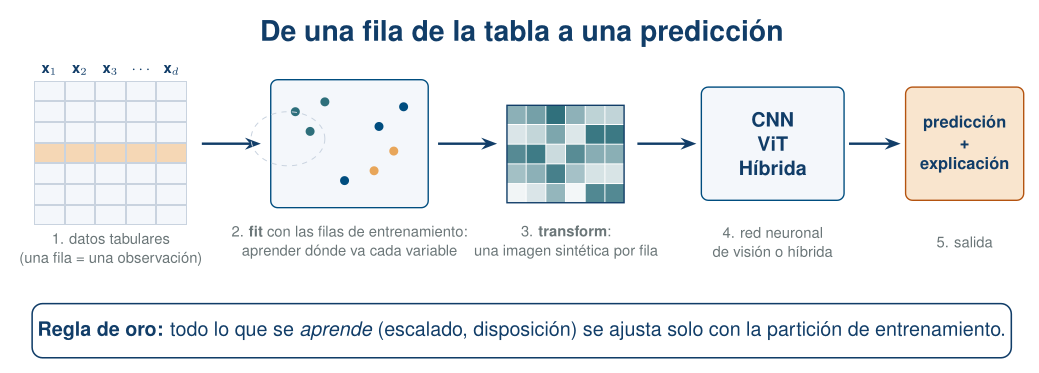

<p style="text-align:center; color:#555555;"><em><strong>Figura 1.</strong> De una fila de la tabla a una predicción. La transformación se <strong>ajusta</strong> con las filas de entrenamiento, cada fila se <strong>transforma</strong> después en una imagen sintética y una red de visión o híbrida aprende de ella. La explicación devuelve los píxeles a las variables originales.</em></p>

<div class="alert alert-info">
<strong>Objetivos de aprendizaje.</strong><br>
Al terminar este notebook deberías ser capaz de transformar un conjunto de datos tabular con varios métodos de TINTOlib, explicar en qué se diferencian las principales familias de métodos, construir modelos CNN, ViT e híbridos (CNN+MLP, ViT+MLP) en PyTorch, <strong>evaluarlos de forma fiable</strong> con validación cruzada repetida, intervalos de confianza y tests estadísticos corregidos, y explicar la CNN y el ViT en términos de las variables originales comprobando que las explicaciones son fieles.
</div>

<div class="alert alert-warning">
<strong>Entorno de ejecución.</strong><br>
El notebook está pensado para <strong>Google Colab</strong>; basta con un entorno gratuito con CPU. Las secciones 1–9 y 11 tardan unos 5 minutos; la evaluación fiable de la Sección 10 entrena cada red 10 veces y tarda unos 12 minutos más con CPU (con GPU es más rápido). REFINED necesita MPI: la celda de configuración lo instala en Colab y, si falla, el notebook omite REFINED y continúa. En local se necesita Python ≥ 3.9 con PyTorch, scikit-learn, SciPy, matplotlib y TINTOlib.
</div>

---
<div style="text-align: right">
<font size=5>
<a href="#indice">Volver al índice</a>
</font>
</div>

<a id="section1" name="section1"></a>
# <font color="#004D7F" size=6>1. Configuración</font>

Colab ya incluye PyTorch, scikit-learn, SciPy y matplotlib. Instalamos **TINTOlib** y, para REFINED, un entorno MPI y `mpi4py`.

In [1]:
%pip install -q TINTOlib
# Opcional, solo para REFINED: un entorno MPI y mpi4py. La última línea indica si REFINED podrá ejecutarse.
!apt-get -qq install -y openmpi-bin libopenmpi-dev > /dev/null 2>&1; pip install -q mpi4py > /dev/null 2>&1
!which mpirun > /dev/null && python -c "import mpi4py" 2>/dev/null && echo "MPI disponible: REFINED se ejecutará" || echo "MPI no disponible: se omitirá REFINED"


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: /opt/homebrew/opt/python@3.11/bin/python3.11 -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.
MPI no disponible: se omitirá REFINED


In [2]:
import os, copy, math, random, shutil, time, warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.patches import Patch
from scipy import stats
from scipy.stats import spearmanr

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, RepeatedStratifiedKFold
from sklearn.preprocessing import MinMaxScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score, roc_auc_score,
                             brier_score_loss)

# TINTOlib: una clase por método de transformación, todas con la misma interfaz fit / transform
from TINTOlib.tinto import TINTO
from TINTOlib.igtd import IGTD
from TINTOlib.refined import REFINED
from TINTOlib.deepInsight import DeepInsight
from TINTOlib.fotomics import Fotomics
from TINTOlib.barGraph import BarGraph
from TINTOlib.featureWrap import FeatureWrap
from TINTOlib.clusters import Clusters

warnings.filterwarnings("ignore")
SEED = 42

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed()
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch", torch.__version__, "| dispositivo:", DEVICE)

# Paleta y un estilo de figura compacto
NAVY, TEAL, ORANGE, GREY = "#113D68", "#2E6F7B", "#E8A65A", "#7F8C9A"
plt.rcParams.update({"figure.dpi": 90, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titlesize": 10, "axes.titlecolor": NAVY, "font.size": 9})

KeyboardInterrupt: 

---
<div style="text-align: right">
<font size=5>
<a href="#indice">Volver al índice</a>
</font>
</div>

<a id="section2" name="section2"></a>
# <font color="#004D7F" size=6>2. El conjunto de datos</font>

Usamos el conjunto **Breast Cancer Wisconsin**, incluido en scikit-learn, así que no hay que descargar nada:

- **569 pacientes** y **30 variables numéricas** calculadas a partir de una imagen digitalizada de una masa mamaria;
- cada una de las **10 medidas** (radio, textura, perímetro, área, suavidad, compacidad, concavidad, puntos cóncavos, simetría y dimensión fractal) aparece tres veces: su **media**, su **error estándar** y su **peor** valor. Estos grupos de variables muy correlacionadas son justo lo que las disposiciones aprendidas intentan aprovechar, por lo que las imágenes son fáciles de interpretar;
- **tarea binaria:** maligno frente a benigno.

> En scikit-learn, `0 = maligno` y `1 = benigno`. Invertimos la etiqueta para que **1 = maligno** sea la clase positiva.

In [ ]:
data = load_breast_cancer(as_frame=True)
df = data.frame.copy()
df.columns = [c.replace(" ", "_") for c in df.columns]
df["target"] = (data.target == 0).astype(int)          # 1 = maligno, 0 = benigno

FEATURES = [c for c in df.columns if c != "target"]
print(f"{df.shape[0]} pacientes x {len(FEATURES)} variables")
df.head()

569 pacientes x 30 variables


,mean_radius,mean_texture,mean_perimeter,mean_area,mean_smoothness,mean_compactness,mean_concavity,mean_concave_points,mean_symmetry,mean_fractal_dimension,...,worst_texture,worst_perimeter,worst_area,worst_smoothness,worst_compactness,worst_concavity,worst_concave_points,worst_symmetry,worst_fractal_dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,1
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,1
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,1
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,1
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,1


TINTOlib espera una **tabla ordenada**: una fila por observación, variables numéricas y la **variable objetivo en la última columna**. Es exactamente lo que tenemos.

La matriz de correlación muestra los bloques de variables muy relacionadas, la estructura que una buena disposición de imagen debería colocar cerca.

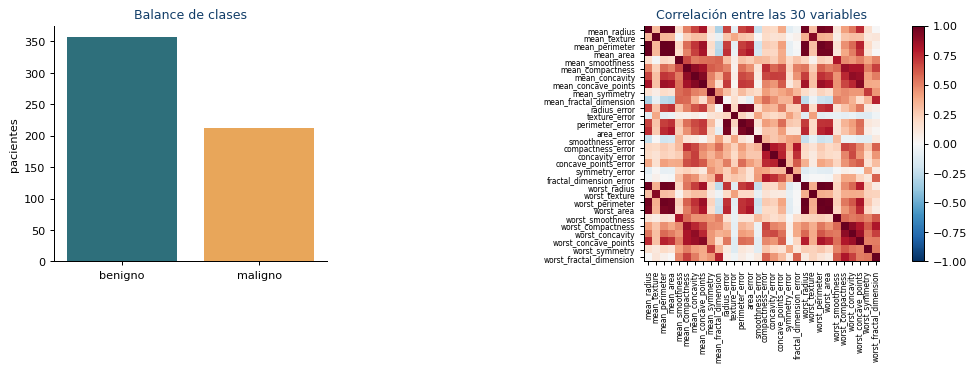

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), gridspec_kw={"width_ratios": [1, 2.4]})

counts = df["target"].map({0: "benigno", 1: "maligno"}).value_counts()
axes[0].bar(counts.index, counts.values, color=[TEAL, ORANGE])
axes[0].set_title("Balance de clases")
axes[0].set_ylabel("pacientes")

im = axes[1].imshow(df[FEATURES].corr(), cmap="RdBu_r", vmin=-1, vmax=1)
axes[1].set_title("Correlación entre las 30 variables")
axes[1].set_xticks(range(len(FEATURES)))
axes[1].set_xticklabels(FEATURES, rotation=90, fontsize=6)
axes[1].set_yticks(range(len(FEATURES)))
axes[1].set_yticklabels(FEATURES, fontsize=6)
fig.colorbar(im, ax=axes[1], fraction=0.03)
plt.tight_layout()
plt.show()

---
<div style="text-align: right">
<font size=5>
<a href="#indice">Volver al índice</a>
</font>
</div>

<a id="section3" name="section3"></a>
# <font color="#004D7F" size=6>3. Primero particionar, después transformar</font>

Muchos métodos de TINTOlib **aprenden** algo de los datos: un escalador, una proyección 2-D, una disposición óptima de las variables. Ese aprendizaje debe usar **solo las filas de entrenamiento**; las filas de validación y test se transforman después con el método congelado, exactamente igual que con un escalador de scikit-learn (Figura 2).

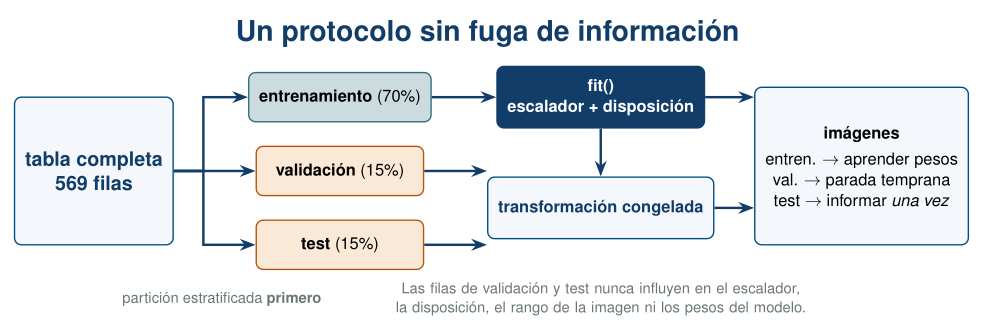

<p style="text-align:center; color:#555555;"><em><strong>Figura 2.</strong> Protocolo sin fuga de información. Primero se particiona la tabla; el escalador y la disposición de la imagen se ajustan con la partición de entrenamiento y se aplican, congelados, a validación y test. La partición de test se usa una sola vez, para informar de los resultados finales.</em></p>

En las secciones 3–9 usamos **una** partición estratificada 70/15/15. Es la forma más clara de seguir el flujo paso a paso, y la Sección 11 la reutiliza para explicar los modelos. **No** basta para estimar el rendimiento de forma fiable con 569 pacientes; la Sección 10 repite todo el flujo con validación cruzada para obtener estimaciones que sí se pueden publicar.

In [ ]:
train_df, temp_df = train_test_split(df, test_size=0.30, stratify=df["target"], random_state=SEED)
val_df, test_df = train_test_split(temp_df, test_size=0.50, stratify=temp_df["target"], random_state=SEED)
train_df, val_df, test_df = [d.reset_index(drop=True) for d in (train_df, val_df, test_df)]

SPLITS = {"train": train_df, "val": val_df, "test": test_df}
for name, d in SPLITS.items():
    print(f"{name:<5}: {len(d):3d} pacientes, {d['target'].mean():.0%} malignos")

train: 398 pacientes, 37% malignos
val  :  85 pacientes, 38% malignos
test :  86 pacientes, 37% malignos


---
<div style="text-align: right">
<font size=5>
<a href="#indice">Volver al índice</a>
</font>
</div>

<a id="section4" name="section4"></a>
# <font color="#004D7F" size=6>4. De filas a imágenes: una galería de métodos</font>

Todos los métodos de TINTOlib siguen los mismos dos pasos:

```python
method.fit(train_df)                          # aprender la transformación con las filas de entrenamiento
method.transform(test_df, folder="img/test")  # escribir una imagen por fila + un CSV índice
```

Los métodos se agrupan en tres familias (Figura 3).

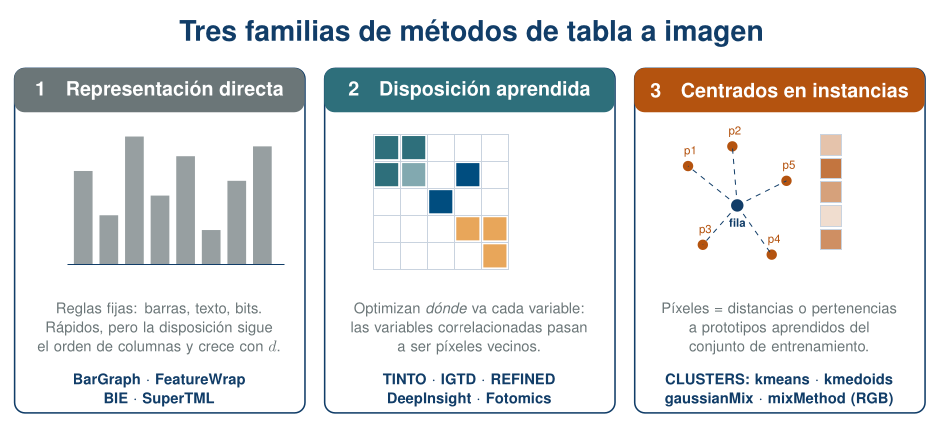

<p style="text-align:center; color:#555555;"><em><strong>Figura 3.</strong> Tres familias de métodos de tabla a imagen. La <strong>representación directa</strong> dibuja los valores con reglas fijas, las <strong>disposiciones aprendidas</strong> optimizan dónde se coloca cada variable y los métodos <strong>centrados en instancias</strong> (CLUSTERS) codifican cómo se relaciona una fila con prototipos aprendidos del conjunto de entrenamiento.</em></p>

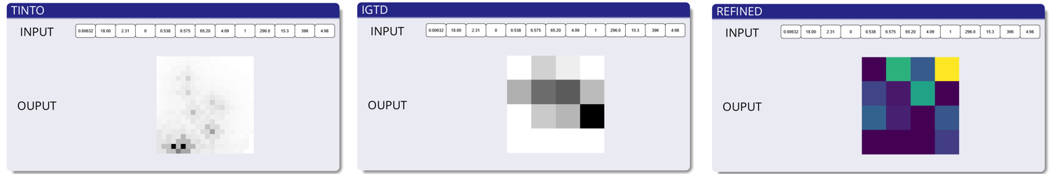

<p style="text-align:center; color:#555555;"><em><strong>Figura 4.</strong> Las tres disposiciones aprendidas clásicas sobre la misma fila de entrada: <strong>TINTO</strong> (proyección PCA o t-SNE, difuminado opcional), <strong>IGTD</strong> (permutación optimizada sobre una rejilla) y <strong>REFINED</strong> (escalado multidimensional más <em>hill-climbing</em>).</em></p>

<a id="section41" name="section41"></a>
## <font color="#004D7F" size=5>4.1. Generación de las imágenes</font>

La función auxiliar de abajo encapsula los dos pasos, escribe las imágenes en disco y las vuelve a leer en el orden de las filas. Recibe las particiones como argumento, de modo que la Sección 10 puede reutilizarla dentro de cada pliegue de la validación cruzada.

<div class="alert alert-info">
<strong>¿PNG o npy?</strong><br>
Los métodos de disposición aprendida pueden guardar la matriz numérica original (<code>format="npy"</code>) en lugar de un PNG. Un PNG se escala en color imagen a imagen, de modo que el nivel absoluto de un píxel no es comparable entre pacientes; <code>npy</code> conserva los valores exactos. Usamos <code>npy</code> siempre que el método lo permite.
</div>

In [ ]:
IMG_ROOT = "tintolib_images"

def to_gray(imgs):
    # Los PNG se leen como RGB(A); se reducen a un canal. Las matrices 2-D pasan sin cambios.
    return imgs[..., :3].mean(-1) if imgs.ndim == 4 else imgs

def read_images(folder):
    # TINTOlib escribe las imágenes y un CSV índice ('images' = ruta relativa, 'values' = etiqueta)
    index = pd.read_csv(os.path.join(folder, "supervised.csv"))
    imgs = []
    for rel_path in index["images"]:
        path = os.path.join(folder, rel_path)
        img = np.load(path) if path.endswith(".npy") else plt.imread(path)
        imgs.append(img.astype(np.float32))
    return np.stack(imgs), index["values"].to_numpy()

def to_images(method, name, splits=None, verbose=True):
    # Ajustar SOLO con la partición de ENTRENAMIENTO y transformar todas las particiones con el método congelado
    splits = SPLITS if splits is None else splits
    out = os.path.join(IMG_ROOT, name)
    shutil.rmtree(out, ignore_errors=True)
    t0 = time.time()
    method.fit(splits["train"])
    images = {}
    for split, frame in splits.items():
        folder = os.path.join(out, split)
        method.transform(frame, folder=folder)
        images[split], labels = read_images(folder)
        assert (labels == frame["target"].to_numpy()).all(), "el orden de las imágenes no coincide con el de las filas"
    if verbose:
        shape = "x".join(str(s) for s in images["train"].shape[1:3])
        print(f"{name:<22} {shape:>7} píxeles   {time.time() - t0:5.1f} s")
    return images

In [ ]:
gallery_methods = {
    # Disposición aprendida (paramétricos)
    "TINTO":              TINTO(problem="supervised", pixels=20, blur=False, format="npy", random_seed=SEED),
    "TINTO + blur":       TINTO(problem="supervised", pixels=20, blur=True, format="npy", random_seed=SEED),
    "IGTD":               IGTD(problem="supervised", scale=[5, 6], max_step=2000, val_step=100, format="npy", random_seed=SEED),
    "REFINED":            REFINED(problem="supervised", hcIterations=5, n_processors=2, format="npy", random_seed=SEED),
    "DeepInsight":        DeepInsight(image_dim=12, problem="supervised", format="npy", random_seed=SEED),
    "Fotomics":           Fotomics(image_dim=12, problem="supervised", format="npy", random_seed=SEED),
    # Representación directa (no paramétricos)
    "BarGraph":           BarGraph(problem="supervised", pixel_width=2, gap=1),
    "FeatureWrap":        FeatureWrap(problem="supervised", size=(8, 8), bins=10),
    # Centrados en instancias (CLUSTERS)
    "CLUSTERS kmedoids":  Clusters(problem="supervised", algorithm="kmedoids", n_clusters=16, random_seed=SEED),
    "CLUSTERS mixMethod": Clusters(problem="supervised", algorithm="mixMethod",
                                   ensamMethod=["kmeans", "gaussianMix", "kmedoids"], n_clusters=16, random_seed=SEED),
}
LEARNED, DIRECT, INSTANCE = "disposición aprendida", "directo", "centrado en instancias"
FAMILY = {"TINTO": LEARNED, "TINTO + blur": LEARNED, "IGTD": LEARNED, "REFINED": LEARNED,
          "DeepInsight": LEARNED, "Fotomics": LEARNED, "BarGraph": DIRECT, "FeatureWrap": DIRECT,
          "CLUSTERS kmedoids": INSTANCE, "CLUSTERS mixMethod": INSTANCE + " (RGB)"}

gallery = {}
for name, method in gallery_methods.items():
    try:
        gallery[name] = to_images(method, name.replace(" ", "_"))
    except Exception as err:                       # REFINED necesita MPI; se omite si MPI no está disponible
        print(f"{name:<22} omitido: {type(err).__name__}: {str(err)[:80]}")

TINTO                    20x20 píxeles     0.2 s
TINTO_+_blur             20x20 píxeles     0.3 s
IGTD                       5x6 píxeles     0.2 s
REFINED                    6x6 píxeles     2.0 s
DeepInsight              12x12 píxeles     0.1 s
Fotomics                 12x12 píxeles     0.1 s
BarGraph                 91x91 píxeles     0.2 s
FeatureWrap                8x8 píxeles     0.3 s
CLUSTERS_kmedoids          4x4 píxeles     0.1 s
CLUSTERS_mixMethod         4x4 píxeles     0.2 s


<a id="section42" name="section42"></a>
## <font color="#004D7F" size=5>4.2. El mismo paciente, diez imágenes</font>

Este es **el mismo paciente de test** dibujado por cada método. Todas las imágenes recodifican la misma fila de 30 números.

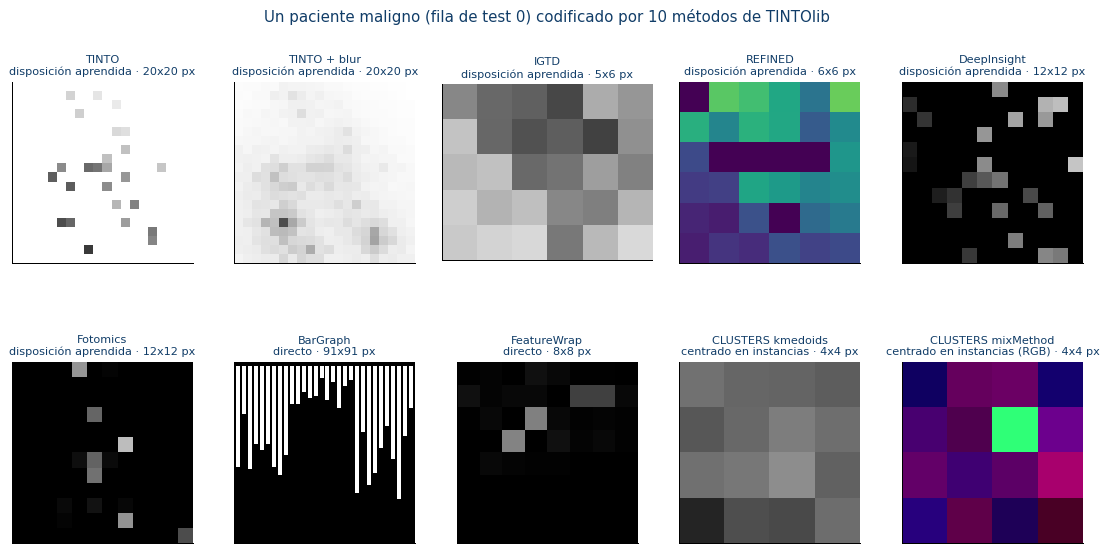

In [ ]:
def show_img(ax, name, img):
    # Mismo mapa de color y rango de valores para todos los pacientes de un método
    if img.ndim == 3:                                   # RGB(A): se muestra tal cual
        ax.imshow(img, interpolation="nearest")
    else:
        train = gallery[name]["train"]
        cmap = getattr(gallery_methods[name], "cmap", None) or "gray"
        ax.imshow(img, cmap=cmap, vmin=train.min(), vmax=train.max(), interpolation="nearest")
    ax.set_xticks([]); ax.set_yticks([])

patient = int(np.flatnonzero(test_df["target"].to_numpy() == 1)[0])   # primer paciente maligno de test

n = len(gallery)
fig, axes = plt.subplots(2, math.ceil(n / 2), figsize=(2.5 * math.ceil(n / 2), 6.2))
for ax in axes.ravel():
    ax.axis("off")
for ax, (name, imgs) in zip(axes.ravel(), gallery.items()):
    img = imgs["test"][patient]
    ax.axis("on")
    show_img(ax, name, img)
    ax.set_title(f"{name}\n{FAMILY[name]} · {img.shape[0]}x{img.shape[1]} px", fontsize=9)
fig.suptitle(f"Un paciente maligno (fila de test {patient}) codificado por {n} métodos de TINTOlib", fontsize=12, color=NAVY)
plt.tight_layout(rect=(0, 0, 1, 0.93))
plt.subplots_adjust(hspace=0.55)
plt.show()

**Qué observar**

- Las **disposiciones aprendidas** (TINTO, IGTD, REFINED, DeepInsight, Fotomics) son compactas: un píxel, o una pequeña mancha, por variable, colocado mediante una proyección o una optimización ajustada con los datos de entrenamiento.
- El **difuminado** de TINTO reparte cada variable entre sus vecinos, algo que favorece a los filtros convolucionales, pero hace más difícil asociar cada píxel a una única variable.
- Las **representaciones directas** (BarGraph, FeatureWrap) siguen el orden de las columnas de la tabla y crecen con el número de variables.
- **CLUSTERS** no dibuja las variables: con `kmedoids`, sus 16 píxeles son distancias a 16 pacientes prototipo aprendidos del conjunto de entrenamiento; `mixMethod` apila tres de estas vistas (k-means, mezcla gaussiana, k-medoids) como los **canales rojo, verde y azul** de una imagen.
- **REFINED** coloca las 30 variables en una rejilla de 6×6 (36 celdas): las celdas sin variable tienen un valor constante, visible como la franja oscura uniforme de la Sección 4.3. La galería lo muestra con su mapa de color por defecto, *viridis*.

<a id="section43" name="section43"></a>
## <font color="#004D7F" size=5>4.3. ¿Se distinguen los pacientes benignos de los malignos?</font>

Para cuatro métodos promediamos las imágenes de entrenamiento de cada clase y las restamos.

<div class="alert alert-info">
<strong>Cómo leer estos mapas.</strong><br>
Todas las imágenes tienen <strong>un único canal</strong>. Los colores son un <em>mapa de color</em> aplicado para la visualización, no canales RGB: las dos primeras columnas usan una escala de grises y la diferencia usa una escala rojo–azul (rojo: el píxel es, en promedio, más alto en los pacientes malignos; azul: más alto en los benignos). Obsérvese que <strong>IGTD pinta oscuros los valores altos</strong> (una convención de TINTOlib), así que en IGTD una variable mayor en los pacientes malignos aparece en <em>azul</em>, mientras que en TINTO aparece en <em>rojo</em>.
</div>

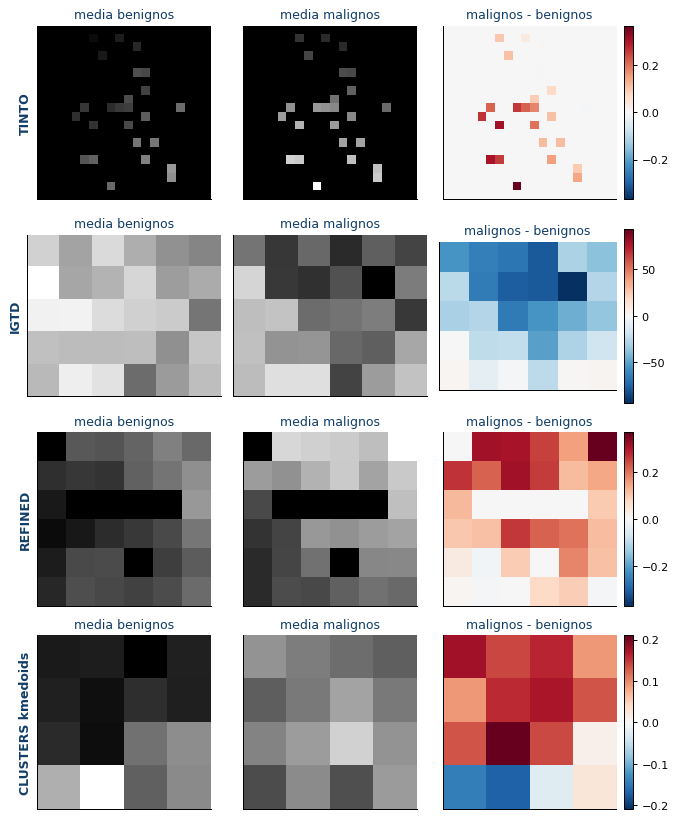

In [ ]:
show = [m for m in ["TINTO", "IGTD", "REFINED", "CLUSTERS kmedoids"] if m in gallery]
y_train = train_df["target"].to_numpy()

fig, axes = plt.subplots(len(show), 3, figsize=(7.6, 2.3 * len(show)))
for row, name in zip(np.atleast_2d(axes), show):
    imgs = to_gray(gallery[name]["train"])
    mean_benign, mean_malig = imgs[y_train == 0].mean(0), imgs[y_train == 1].mean(0)
    diff = mean_malig - mean_benign
    lim = np.abs(diff).max()
    vmin, vmax = min(mean_benign.min(), mean_malig.min()), max(mean_benign.max(), mean_malig.max())
    row[0].imshow(mean_benign, cmap="gray", vmin=vmin, vmax=vmax, interpolation="nearest")
    row[1].imshow(mean_malig, cmap="gray", vmin=vmin, vmax=vmax, interpolation="nearest")
    im = row[2].imshow(diff, cmap="RdBu_r", vmin=-lim, vmax=lim, interpolation="nearest")
    fig.colorbar(im, ax=row[2], fraction=0.046, pad=0.04)
    for ax, title in zip(row, ["media benignos", "media malignos", "malignos - benignos"]):
        ax.set_title(title); ax.set_xticks([]); ax.set_yticks([])
    row[0].set_ylabel(name, fontsize=10, color=NAVY, fontweight="bold")
plt.tight_layout()
plt.show()

La señal de clase es visible a simple vista, y **cada método la expone de forma distinta**. Por eso, en los grandes *benchmarks*, la elección de la transformación importa más que la elección de la red.

---
<div style="text-align: right">
<font size=5>
<a href="#indice">Volver al índice</a>
</font>
</div>

<a id="section5" name="section5"></a>
# <font color="#004D7F" size=6>5. ¿Dónde está cada variable?</font>

Para explicar un modelo entrenado con imágenes sintéticas necesitamos un **mapa de los píxeles a las variables**. Lo calculamos de forma empírica, con un procedimiento válido para cualquier método (Figura 5).

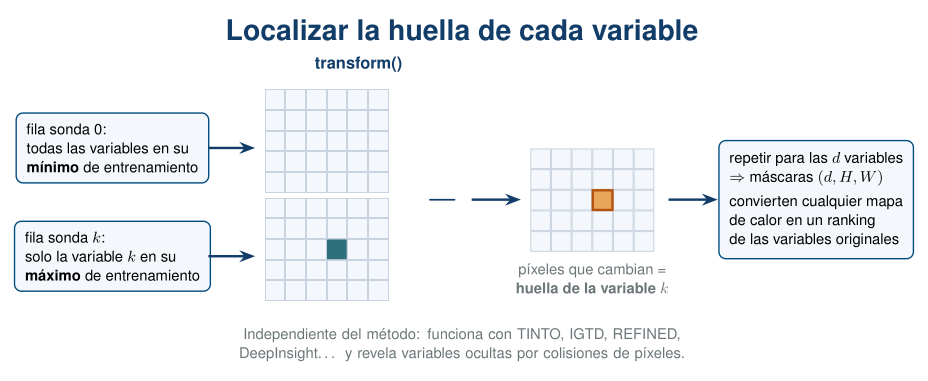

<p style="text-align:center; color:#555555;"><em><strong>Figura 5.</strong> Localizar la huella de cada variable. Una fila sonda con todas las variables en su mínimo de entrenamiento se compara con sondas en las que una sola variable se sube a su máximo; los píxeles que cambian son la huella de esa variable.</em></p>

In [ ]:
MEASURES = ["radius", "texture", "perimeter", "area", "smoothness", "compactness",
            "concavity", "concave_points", "symmetry", "fractal_dimension"]
GROUP_COLOUR = {"mean": TEAL, "error": GREY, "worst": ORANGE}

def group_of(name):
    return "mean" if name.startswith("mean_") else "worst" if name.startswith("worst_") else "error"

def measure_of(name):
    return name.replace("mean_", "").replace("worst_", "").replace("_error", "")

def feature_footprints(method, train_frame=None, threshold=0.5):
    # Máscaras booleanas (n_variables, H, W): qué píxeles cambian cuando cambia cada variable
    train_frame = train_df if train_frame is None else train_frame
    lo, hi = train_frame[FEATURES].min(), train_frame[FEATURES].max()
    rows = [lo.to_numpy(copy=True)]
    for k in range(len(FEATURES)):
        r = lo.to_numpy(copy=True)
        r[k] = hi.iloc[k]
        rows.append(r)
    probe = pd.DataFrame(rows, columns=FEATURES)
    probe["target"] = 0
    folder = os.path.join(IMG_ROOT, "_probe")
    shutil.rmtree(folder, ignore_errors=True)
    method.transform(probe, folder=folder)
    imgs = to_gray(read_images(folder)[0])
    diff = np.abs(imgs[1:] - imgs[0])
    peak = diff.reshape(len(FEATURES), -1).max(axis=1)
    masks = diff >= threshold * peak[:, None, None]
    masks[peak == 0] = False          # variables que no aparecen en la imagen
    return masks

def plot_layout(masks, title, ax, label="name"):
    # Colorear cada huella según su grupo y etiquetarla con el nombre o el número de la medida
    H, W = masks.shape[1:]
    canvas = np.ones((H, W, 3)) * np.array([0.96, 0.97, 0.98])
    for k, m in enumerate(masks):
        canvas[m] = np.array(mcolors.to_rgb(GROUP_COLOUR[group_of(FEATURES[k])]))
    ax.imshow(canvas, interpolation="nearest")
    ax.set_xticks(np.arange(-0.5, W, 1), minor=True)
    ax.set_yticks(np.arange(-0.5, H, 1), minor=True)
    ax.grid(which="minor", color="white", lw=2 if H < 10 else 0.8)
    ax.tick_params(which="both", length=0)
    ax.set_xticklabels([]); ax.set_yticklabels([])
    for k, m in enumerate(masks):
        if m.any():
            r, c = np.argwhere(m).mean(0)
            meas = measure_of(FEATURES[k])
            text = meas.replace("_", "\n") if label == "name" else str(MEASURES.index(meas) + 1)
            ax.text(c, r, text, ha="center", va="center", color="white", fontweight="bold",
                    fontsize=9 if label == "name" else 7.5)
    ax.set_title(title, fontsize=11)

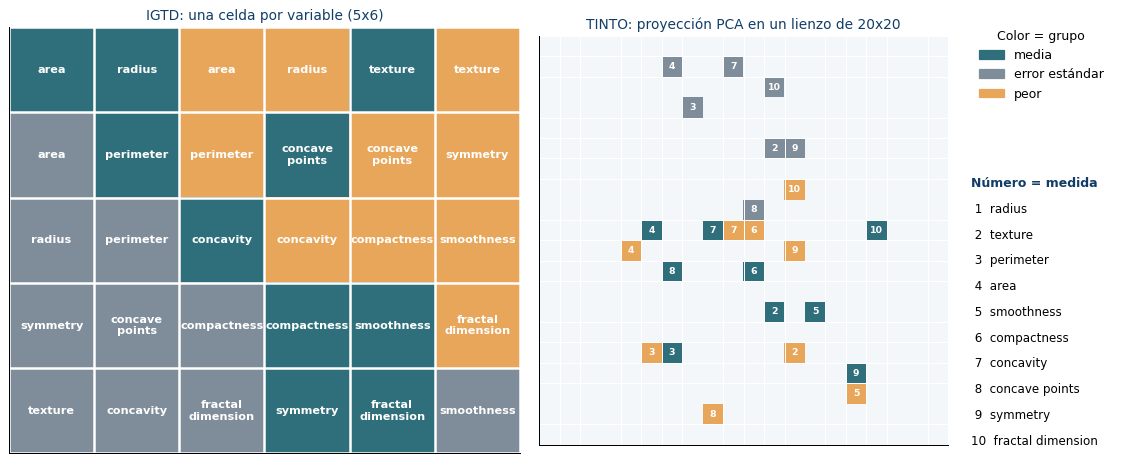

TINTO: 25 de 30 variables son visibles.
Ocultas porque otra variable se proyectó en el mismo píxel: mean_radius, radius_error, smoothness_error, compactness_error, worst_radius


In [ ]:
layout = {name: feature_footprints(gallery_methods[name]) for name in ["IGTD", "TINTO"]}

fig = plt.figure(figsize=(13, 5.2))
gs = fig.add_gridspec(1, 3, width_ratios=[1.25, 1, 0.42])
ax0, ax1, ax2 = fig.add_subplot(gs[0]), fig.add_subplot(gs[1]), fig.add_subplot(gs[2])
plot_layout(layout["IGTD"], "IGTD: una celda por variable (5x6)", ax0, label="name")
plot_layout(layout["TINTO"], "TINTO: proyección PCA en un lienzo de 20x20", ax1, label="number")

ax2.axis("off")
ax2.legend(handles=[Patch(color=GROUP_COLOUR[g], label=l) for g, l in
                    [("mean", "media"), ("error", "error estándar"), ("worst", "peor")]],
           loc="upper left", frameon=False, fontsize=10, title="Color = grupo", title_fontsize=10)
ax2.text(0.02, 0.62, "Número = medida", fontsize=10, fontweight="bold", color=NAVY, transform=ax2.transAxes)
for i, m in enumerate(MEASURES, 1):
    ax2.text(0.02, 0.62 - 0.058 * i, f"{i:>2}  {m.replace('_', ' ')}", fontsize=9.5, transform=ax2.transAxes)
plt.tight_layout()
plt.show()

hidden = [FEATURES[k] for k, m in enumerate(layout["TINTO"]) if not m.any()]
print(f"TINTO: {len(FEATURES) - len(hidden)} de {len(FEATURES)} variables son visibles.")
print("Ocultas porque otra variable se proyectó en el mismo píxel:", ", ".join(hidden))

**Cómo leer los mapas**

- **IGTD** asigna a cada variable su propia celda y coloca juntas las variables relacionadas: las medidas de tamaño (radio, perímetro, área) aparecen agrupadas, igual que las de forma (concavidad, puntos cóncavos, compacidad).
- **TINTO** proyecta las variables con PCA. Las variables con perfiles muy parecidos se proyectan en el **mismo píxel** y solo una de ellas queda visible. Más píxeles o la opción t-SNE pueden separarlas.

<div class="alert alert-warning">
<strong>Por qué importa.</strong><br>
Una imagen que oculta variables es un motivo concreto para usar <strong>redes híbridas</strong>: una rama MLP alimentada con la tabla original sigue viendo todas las variables.
</div>

---
<div style="text-align: right">
<font size=5>
<a href="#indice">Volver al índice</a>
</font>
</div>

<a id="section6" name="section6"></a>
# <font color="#004D7F" size=6>6. Modelos de referencia clásicos</font>

Toda comparación honesta empieza con modelos tabulares sólidos entrenados exactamente con los mismos datos. El escalador se ajusta solo con las filas de entrenamiento; la misma tabla escalada alimentará la rama MLP de las redes híbridas.

Informamos de métricas basadas en un umbral (exactitud, exactitud equilibrada, F1 de la clase maligna), de una métrica de ordenación (ROC-AUC) y de la **puntuación de Brier**, el error cuadrático medio de las probabilidades predichas. La puntuación de Brier es una *regla de puntuación propia*: premia probabilidades que discriminan bien y además están bien calibradas, y no se satura cuando el ROC-AUC ya está cerca de 1. Cuanto menor, mejor:

$$\text{Brier} = \frac{1}{N}\sum_{i=1}^{N}(p_i - y_i)^2,$$

donde $p_i$ es la probabilidad predicha de malignidad e $y_i \in \{0, 1\}$ la etiqueta real. Un modelo perfecto obtiene 0; predecir siempre la prevalencia (37% de malignos) da 0,234, y predecir siempre 0,5 da 0,25.

In [ ]:
scaler = MinMaxScaler().fit(train_df[FEATURES])
X_tab = {s: scaler.transform(d[FEATURES]).astype(np.float32) for s, d in SPLITS.items()}
y = {s: d["target"].to_numpy() for s, d in SPLITS.items()}

# Nombres de métricas y modelos, definidos una vez y reutilizados en todas las tablas
ACC, BACC, F1, AUC, BRIER = "exactitud", "exact. equilibrada", "F1 (maligno)", "ROC-AUC", "Brier"
LOGREG, GBOOST = "Regresión logística", "Gradient boosting"

def metrics(y_true, prob, threshold=0.5):
    pred = (prob >= threshold).astype(int)
    return {ACC: accuracy_score(y_true, pred),
            BACC: balanced_accuracy_score(y_true, pred),
            F1: f1_score(y_true, pred),
            AUC: roc_auc_score(y_true, prob),
            BRIER: brier_score_loss(y_true, prob)}

def report(name, y_true, prob):
    return {"modelo": name, **metrics(y_true, prob)}

baseline_results = []
logreg = LogisticRegression(max_iter=5000).fit(X_tab["train"], y["train"])
baseline_results.append(report(LOGREG + " (tabla)", y["test"], logreg.predict_proba(X_tab["test"])[:, 1]))

hgb = HistGradientBoostingClassifier(random_state=SEED).fit(X_tab["train"], y["train"])
baseline_results.append(report(GBOOST + " (tabla)", y["test"], hgb.predict_proba(X_tab["test"])[:, 1]))

pd.DataFrame(baseline_results).set_index("modelo").round(3)

,exactitud,exact. equilibrada,F1 (maligno),ROC-AUC,Brier
modelo,,,,,
Regresión logística (tabla),0.965,0.953,0.951,1.000,0.026
Gradient boosting (tabla),0.977,0.969,0.968,0.999,0.019


Los dos modelos de referencia ya son muy buenos (exactitud 0,965 y 0,977) y, en esta partición de test, su ROC-AUC está saturado (≥ 0,999): ya no distingue entre modelos, por eso seguimos también la puntuación de Brier (0,026 y 0,019). El objetivo es entender el flujo, no batir una clasificación; en conjuntos más difíciles, de alta dimensión o pequeños, el panorama cambia (véase el *benchmark* de las referencias).

---
<div style="text-align: right">
<font size=5>
<a href="#indice">Volver al índice</a>
</font>
</div>

<a id="section7" name="section7"></a>
# <font color="#004D7F" size=6>7. Imágenes para las redes neuronales</font>

Para los modelos profundos elegimos **un** método. Usamos **IGTD** porque cada variable tiene su propia celda, lo que hace exactas las explicaciones de la Sección 11:

- `scale=[5, 6]` da exactamente 30 celdas para nuestras 30 variables, y `zoom=4` amplía cada celda a un bloque de 4x4, de modo que la imagen es de **20x24 píxeles**;
- con un tamaño de parche de 4 en el ViT, **cada uno de los 30 tokens del ViT es exactamente una variable**;
- `format="npy"` conserva los valores numéricos exactos.

El método se crea con una pequeña función, `make_method()`, para que la Sección 10 pueda construir una copia nueva, sin ajustar, dentro de cada pliegue de la validación cruzada.

<div class="alert alert-warning">
<strong>Explorar otros métodos.</strong><br>
Prueba más adelante `METHOD = "TINTO"` u otro método de lo que hayamos creado y vuelve a ejecutar el notebook desde aquí.
</div>

In [ ]:
METHOD = "IGTD"     # o "TINTO"
PATCH = 4           # tamaño de parche del ViT (debe dividir el tamaño de la imagen)

def make_method(seed=SEED):
    # Una transformación nueva, sin ajustar
    if METHOD == "IGTD":
        return IGTD(problem="supervised", scale=[5, 6], max_step=2000, val_step=100,
                    zoom=4, format="npy", random_seed=seed)
    return TINTO(problem="supervised", pixels=20, blur=False, format="npy", random_seed=seed)

model_method = make_method()
raw = to_images(model_method, f"model_{METHOD}")
masks = feature_footprints(model_method)            # huella en píxeles de cada variable, usada en XAI
H, W = raw["train"].shape[-2:]
print("tamaño de imagen:", (H, W), "| variables visibles:", int(sum(m.any() for m in masks)))

model_IGTD               20x24 píxeles     0.2 s
tamaño de imagen: (20, 24) | variables visibles: 30


<a id="section71" name="section71"></a>
## <font color="#004D7F" size=5>7.1. Un problema real: escalado dependiente del lote</font>

Una imagen sintética solo es útil si **el mismo paciente produce siempre la misma imagen**. Podemos comprobarlo: el valor de la celda de cada variable debería ser una función fija de esa variable (escalada con el escalador de entrenamiento), sea cual sea la partición a la que pertenece el paciente.

La función de abajo compara tres hipótesis sobre cómo se relacionan los píxeles guardados con las variables escaladas y elige la que las reproduce exactamente, partición a partición:

1. **tal cual**: los píxeles ya son los valores escalados (TINTO);
2. **invertido, rango de entrenamiento**: los píxeles son `255 · (1 − valor)` con el rango de entrenamiento (lo esperable en IGTD);
3. **invertido, rango del lote**: los píxeles se reescalan con el mínimo y el máximo *del lote que se está transformando*.

<div class="alert alert-warning">
<strong>Qué encontramos.</strong><br>
En TINTOlib 1.3.1, IGTD reescala cada llamada a <code>transform()</code> con el mínimo y el máximo de las filas que recibe. Nuestra partición de validación llega a 1,28 veces el máximo de entrenamiento, así que sus imágenes quedan comprimidas respecto a las de entrenamiento. La red ve entonces una distribución desplazada en validación y test: <strong>curvas de validación ruidosas y probabilidades mal calibradas</strong> (ROC-AUC alto pero exactitud baja). Deshacemos el desplazamiento de forma explícita para que todas las particiones estén en la escala de entrenamiento. El problema se ha comunicado a los desarrolladores.
</div>

In [ ]:
AS_SAVED, INV_TRAIN, INV_BATCH = ("tal cual", "invertido, rango de entrenamiento",
                                  "invertido, rango del lote")

def match_error(img, z, masks):
    # media de |valor de la celda - variable escalada| sobre las variables visibles
    errs = [np.abs(img[:, m].mean(1) - z[:, k]).mean() for k, m in enumerate(masks) if m.any()]
    return float(np.mean(errs))

def restore_scale(raw_split, z, masks):
    # Lleva las imágenes de una partición a la escala de ENTRENAMIENTO: tensor (N, 1, H, W), hipótesis elegida, errores
    a = raw_split / 255.0 if raw_split.max() > 1.5 else raw_split
    lo, hi = z.min(), z.max()                             # z: variables ya escaladas con el escalador de entrenamiento
    candidates = {AS_SAVED: a, INV_TRAIN: 1 - a, INV_BATCH: lo + (1 - a) * (hi - lo)}
    errors = {k: match_error(v, z, masks) for k, v in candidates.items()}
    best = min(errors, key=errors.get)
    return candidates[best][:, None].astype(np.float32), best, errors

X_img = {}
for split in SPLITS:
    X_img[split], best, errors = restore_scale(raw[split], X_tab[split], masks)
    print(f"{split:<5} rango de variables [{X_tab[split].min():+.2f}, {X_tab[split].max():.2f}]  ->  "
          f"mejor ajuste: {best:<36}" + "  ".join(f"{k}: {v:.3f}" for k, v in errors.items()))

assert H % PATCH == 0 and W % PATCH == 0, "elige un PATCH que divida el tamaño de la imagen"

train rango de variables [+0.00, 1.00]  ->  mejor ajuste: invertido, rango de entrenamiento   tal cual: 0.566  invertido, rango de entrenamiento: 0.000  invertido, rango del lote: 0.000
val   rango de variables [+0.00, 1.28]  ->  mejor ajuste: invertido, rango del lote           tal cual: 0.582  invertido, rango de entrenamiento: 0.054  invertido, rango del lote: 0.000
test  rango de variables [-0.10, 1.07]  ->  mejor ajuste: invertido, rango del lote           tal cual: 0.516  invertido, rango de entrenamiento: 0.050  invertido, rango del lote: 0.000


Tras la corrección, cada celda contiene el valor escalado de la variable (claro = alto) en la **escala de entrenamiento**, en todas las particiones. Los valores ligeramente superiores a 1 en validación o test se mantienen: son reales, porque esos pacientes superan el máximo de entrenamiento, y la rama MLP ve exactamente los mismos números.

<a id="section72" name="section72"></a>
## <font color="#004D7F" size=5>7.2. Tensores finales</font>

tensor de imágenes: (398, 1, 20, 24) | tokens por imagen para el ViT: 30


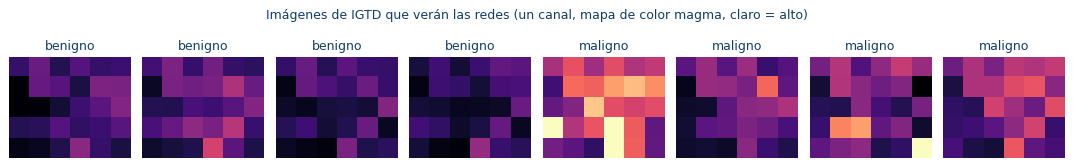

In [ ]:
print("tensor de imágenes:", X_img["train"].shape, "| tokens por imagen para el ViT:", (H // PATCH) * (W // PATCH))

fig, axes = plt.subplots(1, 8, figsize=(12, 2.0))
examples = list(np.flatnonzero(y["train"] == 0)[:4]) + list(np.flatnonzero(y["train"] == 1)[:4])
for ax, i in zip(axes, examples):
    ax.imshow(X_img["train"][i, 0], cmap="magma", vmin=0, vmax=1, interpolation="nearest")
    ax.set_title("maligno" if y["train"][i] else "benigno"); ax.axis("off")
plt.suptitle(f"Imágenes de {METHOD} que verán las redes (un canal, mapa de color magma, claro = alto)",
             color=NAVY, fontsize=10)
plt.tight_layout()
plt.show()

**Cómo leer estas imágenes**

<div class="alert alert-info">
<strong>Un solo canal, coloreado para verlo mejor.</strong><br>
Cada imagen es una matriz de 20×24 números con <strong>un único canal</strong>: lo que recibe la red es un tensor de forma <code>(1, 20, 24)</code>, no una imagen en color. Los colores los añade <code>matplotlib</code> al aplicar el mapa de color <em>magma</em>, que asigna el negro y el morado a los valores bajos y el naranja y el amarillo claro a los altos. Se usa en lugar de la escala de grises porque es perceptualmente uniforme: el ojo distingue mejor diferencias pequeñas de valor.
</div>

- **Cada bloque de 4×4 píxeles es una variable.** IGTD coloca las 30 variables en una rejilla de 5×6 celdas y `zoom=4` amplía cada celda a un bloque de 4×4, por eso se ven 5 filas y 6 columnas de bloques. La variable que corresponde a cada bloque se obtiene con las huellas (`masks`) calculadas en esta sección.
- **Claro = valor alto.** Tras la corrección de la Sección 7.1, cada bloque contiene el valor de su variable escalado entre 0 (mínimo de entrenamiento) y 1 (máximo de entrenamiento). Es la convención contraria a la de las imágenes IGTD originales de TINTOlib, que pintan oscuros los valores altos.
- **Por qué los malignos son más claros.** Casi todas las variables (tamaño, concavidad, puntos cóncavos, compacidad…) tienen valores mayores en los tumores malignos, así que sus imágenes tienen más bloques claros. Como IGTD coloca juntas las variables correlacionadas, las zonas claras tienden a agruparse.
- **Las clases se solapan.** Algunos pacientes malignos tienen imágenes parecidas a las de los benignos; por eso el problema no es trivial y hay que evaluarlo como en la Sección 10.
- Los ejemplos son los cuatro primeros pacientes de cada clase en la partición de entrenamiento: ilustran el patrón, no lo demuestran. La Sección 4.3 compara las imágenes medias de cada clase.
- En validación y test algunos valores superan ligeramente 1 (pacientes por encima del máximo de entrenamiento). Con `vmin=0, vmax=1` esos píxeles se muestran saturados en el color más claro, pero la red recibe su valor real.

---
<div style="text-align: right">
<font size=5>
<a href="#indice">Volver al índice</a>
</font>
</div>

<a id="section8" name="section8"></a>
# <font color="#004D7F" size=6>8. Cuatro arquitecturas</font>

Las ramas de imagen se escriben como **codificadores** que devuelven un *embedding*, de modo que el mismo código sirve para los modelos solo imagen y para los híbridos (Figura 6).

| Modelo | Rama de imagen | Rama tabular | Fusión |
|---|---|---|---|
| **CNN** | red convolucional pequeña | ninguna | ninguna |
| **ViT** | Vision Transformer con parches de 4x4 | ninguna | ninguna |
| **HyCNN** | la misma CNN | MLP sobre las 30 variables originales | concatenación |
| **HyViT** | el mismo ViT | MLP sobre las 30 variables originales | concatenación |

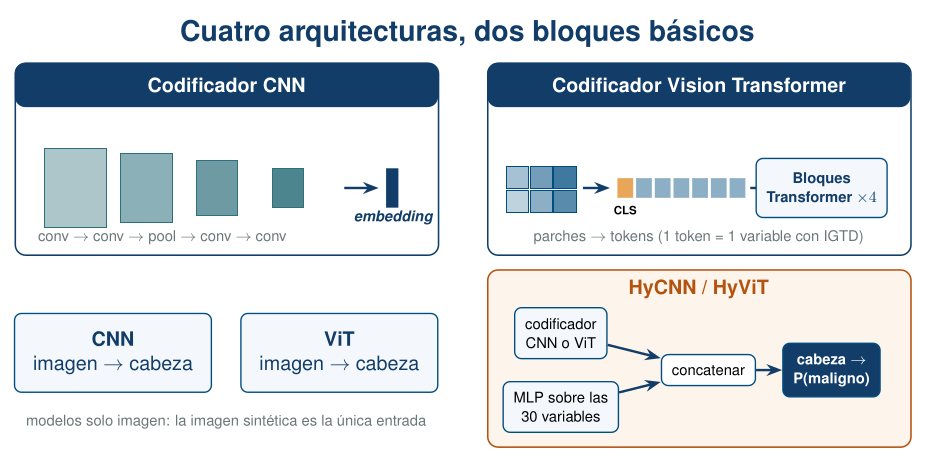

<p style="text-align:center; color:#555555;"><em><strong>Figura 6.</strong> Cuatro arquitecturas construidas con dos codificadores. Los modelos solo imagen usan únicamente la imagen sintética; los híbridos concatenan el <em>embedding</em> de la imagen con un <em>embedding</em> MLP de las variables originales antes de la cabeza de clasificación.</em></p>

<a id="section81" name="section81"></a>
## <font color="#004D7F" size=5>8.1. Codificador CNN</font>

In [ ]:
class CNNEncoder(nn.Module):
    # Dos etapas convolucionales y global average pooling -> embedding
    def __init__(self, in_ch=1, width=32):
        super().__init__()
        def block(c_in, c_out):
            return nn.Sequential(nn.Conv2d(c_in, c_out, 3, padding=1), nn.BatchNorm2d(c_out), nn.ReLU())
        self.stage1 = nn.Sequential(block(in_ch, width), block(width, width), nn.MaxPool2d(2))
        self.stage2 = nn.Sequential(block(width, 2 * width), block(2 * width, 2 * width))  # Grad-CAM mira aquí
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.out_dim = 2 * width

    def forward(self, x):
        return self.pool(self.stage2(self.stage1(x))).flatten(1)

<a id="section82" name="section82"></a>
## <font color="#004D7F" size=5>8.2. Codificador Vision Transformer</font>

El ViT se escribe desde cero en pocas líneas. Cada bloque transformer guarda sus **pesos de atención**, que necesitamos para el *attention rollout*.

In [ ]:
class TransformerBlock(nn.Module):
    def __init__(self, dim, heads, mlp_ratio=2.0, dropout=0.1):
        super().__init__()
        self.norm1 = nn.LayerNorm(dim)
        self.attn = nn.MultiheadAttention(dim, heads, dropout=dropout, batch_first=True)
        self.norm2 = nn.LayerNorm(dim)
        hidden = int(dim * mlp_ratio)
        self.mlp = nn.Sequential(nn.Linear(dim, hidden), nn.GELU(), nn.Dropout(dropout),
                                 nn.Linear(hidden, dim), nn.Dropout(dropout))
        self.last_attn = None

    def forward(self, x):
        h = self.norm1(x)
        a, w = self.attn(h, h, h, need_weights=True, average_attn_weights=False)
        self.last_attn = w.detach()                  # (batch, heads, tokens, tokens)
        x = x + a
        return x + self.mlp(self.norm2(x))


class ViTEncoder(nn.Module):
    # Parches -> embedding lineal + token [CLS] + posiciones -> bloques transformer -> embedding de [CLS]
    def __init__(self, img_size, patch=PATCH, in_ch=1, dim=64, depth=4, heads=4, dropout=0.1):
        super().__init__()
        self.grid = (img_size[0] // patch, img_size[1] // patch)
        n_tokens = self.grid[0] * self.grid[1]
        self.patch_embed = nn.Conv2d(in_ch, dim, kernel_size=patch, stride=patch)
        self.cls = nn.Parameter(torch.zeros(1, 1, dim))
        self.pos = nn.Parameter(torch.zeros(1, n_tokens + 1, dim))
        nn.init.trunc_normal_(self.cls, std=0.02)
        nn.init.trunc_normal_(self.pos, std=0.02)
        self.drop = nn.Dropout(dropout)
        self.blocks = nn.ModuleList([TransformerBlock(dim, heads, dropout=dropout) for _ in range(depth)])
        self.norm = nn.LayerNorm(dim)
        self.out_dim = dim

    def forward(self, x):
        tokens = self.patch_embed(x).flatten(2).transpose(1, 2)            # (batch, n_tokens, dim)
        cls = self.cls.expand(tokens.shape[0], -1, -1)
        tokens = self.drop(torch.cat([cls, tokens], dim=1) + self.pos)
        for block in self.blocks:
            tokens = block(tokens)
        return self.norm(tokens[:, 0])                                     # el token [CLS]

<a id="section83" name="section83"></a>
## <font color="#004D7F" size=5>8.3. Cabezas solo imagen e híbridas</font>

In [ ]:
class ImageClassifier(nn.Module):
    # CNN o ViT solos: imagen -> logit (la entrada tabular se ignora)
    def __init__(self, encoder):
        super().__init__()
        self.encoder = encoder
        self.head = nn.Sequential(nn.Dropout(0.2), nn.Linear(encoder.out_dim, 1))

    def forward(self, img, tab=None):
        return self.head(self.encoder(img)).squeeze(1)


class HybridClassifier(nn.Module):
    # HyNN: rama de imagen (CNN o ViT) + rama MLP sobre las variables originales, fusionadas por concatenación
    def __init__(self, encoder, n_tab, hidden=64):
        super().__init__()
        self.encoder = encoder
        self.mlp = nn.Sequential(nn.Linear(n_tab, hidden), nn.ReLU(), nn.Dropout(0.2),
                                 nn.Linear(hidden, hidden), nn.ReLU())
        self.head = nn.Sequential(nn.Dropout(0.2), nn.Linear(encoder.out_dim + hidden, 64),
                                  nn.ReLU(), nn.Linear(64, 1))

    def forward(self, img, tab):
        z = torch.cat([self.encoder(img), self.mlp(tab)], dim=1)
        return self.head(z).squeeze(1)


N_TAB = len(FEATURES)
BUILDERS = {
    "CNN":   lambda: ImageClassifier(CNNEncoder()),
    "ViT":   lambda: ImageClassifier(ViTEncoder((H, W))),
    "HyCNN": lambda: HybridClassifier(CNNEncoder(), N_TAB),
    "HyViT": lambda: HybridClassifier(ViTEncoder((H, W)), N_TAB),
}
for name, build in BUILDERS.items():
    n_params = sum(p.numel() for p in build().parameters())
    print(f"{name:<6} {n_params:>8,} parámetros entrenables")

CNN      65,441 parámetros entrenables
ViT     137,217 parámetros entrenables
HyCNN    79,841 parámetros entrenables
HyViT   151,617 parámetros entrenables


---
<div style="text-align: right">
<font size=5>
<a href="#indice">Volver al índice</a>
</font>
</div>

<a id="section9" name="section9"></a>
# <font color="#004D7F" size=6>9. Entrenamiento con una partición</font>

<a id="section91" name="section91"></a>
## <font color="#004D7F" size=5>9.1. Una receta de entrenamiento estable</font>

Con solo 398 pacientes de entrenamiento y 85 de validación, las curvas de entrenamiento son ruidosas por naturaleza: basta un paciente de validación mal clasificado con mucha confianza para que la pérdida dé un salto. Además de corregir la escala de entrada (Sección 7.1), la receta de abajo usa herramientas estándar que suavizan la optimización:

| Ingrediente | Por qué |
|---|---|
| **AdamW** con una tasa de aprendizaje moderada (5e-4) y *weight decay* | pasos más pequeños y regularizados |
| **Calentamiento lineal + decaimiento coseno** de la tasa de aprendizaje | evita la inestabilidad inicial, sobre todo en el ViT, y refina al final |
| **Suavizado de etiquetas** (0,05) | evita logits demasiado confiados, que provocan picos de pérdida en un conjunto de validación pequeño |
| **Recorte del gradiente** (norma 1,0) | limita actualizaciones grandes ocasionales |
| **Parada temprana** según la pérdida de validación (paciencia 20) | conserva los pesos de la mejor época |

La receta se **fija de antemano** y no se ajusta con los datos de test. Las funciones de entrenamiento reciben los datos como un diccionario `{"img", "tab", "y"}` de particiones, para que la Sección 10 pueda llamarlas dentro de cada pliegue.

In [ ]:
def make_loader(data, split, shuffle=False, batch_size=32, seed=SEED):
    ds = TensorDataset(torch.from_numpy(data["img"][split]), torch.from_numpy(data["tab"][split]),
                       torch.from_numpy(data["y"][split].astype(np.float32)))
    gen = torch.Generator().manual_seed(seed)
    return DataLoader(ds, batch_size=batch_size, shuffle=shuffle, drop_last=shuffle, generator=gen)

@torch.no_grad()
def predict_logits(model, img, tab, batch_size=256):
    model.eval()
    out = []
    for i in range(0, len(img), batch_size):
        xb = torch.as_tensor(img[i:i + batch_size], device=DEVICE)
        tb = torch.as_tensor(tab[i:i + batch_size], device=DEVICE)
        out.append(model(xb, tb).cpu())
    return torch.cat(out)

def predict_proba(model, img, tab):
    return torch.sigmoid(predict_logits(model, img, tab)).numpy()

def train(model, data, epochs=80, lr=5e-4, weight_decay=1e-2, warmup=5, patience=20, smoothing=0.05, clip=1.0, seed=SEED):
    # data = {"img": {...}, "tab": {...}, "y": {...}} con particiones "train" y "val"
    model = model.to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    schedule = lambda e: (e + 1) / warmup if e < warmup else 0.5 * (1 + math.cos(math.pi * (e - warmup) / (epochs - warmup)))
    sched = torch.optim.lr_scheduler.LambdaLR(opt, schedule)
    loss_fn = nn.BCEWithLogitsLoss()
    train_loader = make_loader(data, "train", shuffle=True, seed=seed)
    y_val = torch.as_tensor(data["y"]["val"], dtype=torch.float32)
    history = {"train_loss": [], "val_loss": [], "val_auc": []}
    best_loss, best_state, wait = np.inf, None, 0
    for epoch in range(epochs):
        model.train()
        total, n = 0.0, 0
        for img, tab, target in train_loader:
            img, tab, target = img.to(DEVICE), tab.to(DEVICE), target.to(DEVICE)
            soft_target = target * (1 - smoothing) + 0.5 * smoothing
            opt.zero_grad()
            loss = loss_fn(model(img, tab), soft_target)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), clip)
            opt.step()
            total += loss.item() * len(target)
            n += len(target)
        sched.step()
        val_logits = predict_logits(model, data["img"]["val"], data["tab"]["val"])
        val_loss = loss_fn(val_logits, y_val).item()
        history["train_loss"].append(total / n)
        history["val_loss"].append(val_loss)
        history["val_auc"].append(roc_auc_score(data["y"]["val"], val_logits.numpy()))
        if val_loss < best_loss - 1e-4:
            best_loss, best_state, wait = val_loss, copy.deepcopy(model.state_dict()), 0
        else:
            wait += 1
            if wait >= patience:
                break
    model.load_state_dict(best_state)
    return model, history

<a id="section92" name="section92"></a>
## <font color="#004D7F" size=5>9.2. Un primer vistazo a los resultados</font>

CNN    entrenado en  17.7 s, 59 épocas
ViT    entrenado en  10.0 s, 41 épocas
HyCNN  entrenado en  10.7 s, 37 épocas
HyViT  entrenado en  16.4 s, 69 épocas


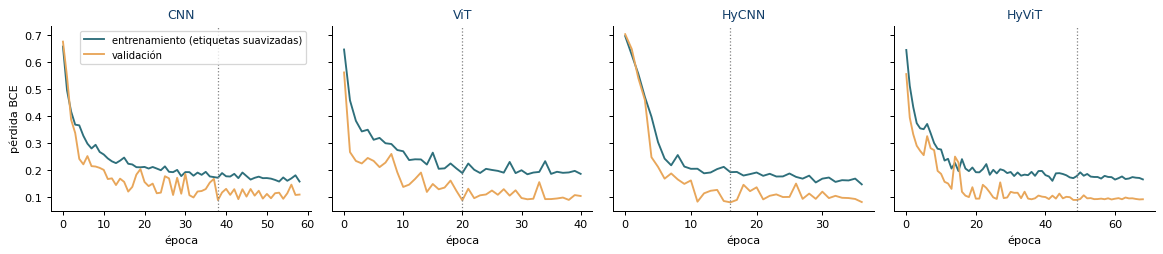

,exactitud,exact. equilibrada,F1 (maligno),ROC-AUC,Brier
modelo,,,,,
Regresión logística (tabla),0.965,0.953,0.951,1.000,0.026
Gradient boosting (tabla),0.977,0.969,0.968,0.999,0.019
CNN (imagen),0.977,0.969,0.968,1.000,0.015
ViT (imagen),1.000,1.000,1.000,1.000,0.003
HyCNN (imagen + tabla),1.000,1.000,1.000,1.000,0.007
HyViT (imagen + tabla),0.988,0.984,0.984,1.000,0.005


In [ ]:
SINGLE = {"img": X_img, "tab": X_tab, "y": y}            # la partición 70/15/15 de la Sección 3
models, histories, deep_results = {}, {}, []
for name, build in BUILDERS.items():
    set_seed()                                   # mismas condiciones iniciales para todos los modelos
    t0 = time.time()
    models[name], histories[name] = train(build(), SINGLE)
    prob = predict_proba(models[name], X_img["test"], X_tab["test"])
    deep_results.append(report(name + (" (imagen + tabla)" if name.startswith("Hy") else " (imagen)"), y["test"], prob))
    print(f"{name:<6} entrenado en {time.time() - t0:5.1f} s, {len(histories[name]['val_loss'])} épocas")

fig, axes = plt.subplots(1, 4, figsize=(13, 2.9), sharey=True)
for ax, (name, h) in zip(axes, histories.items()):
    ax.plot(h["train_loss"], color=TEAL, label="entrenamiento (etiquetas suavizadas)")
    ax.plot(h["val_loss"], color=ORANGE, label="validación")
    ax.axvline(int(np.argmin(h["val_loss"])), color="grey", ls=":", lw=1)
    ax.set_title(name); ax.set_xlabel("época")
axes[0].set_ylabel("pérdida BCE"); axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

pd.DataFrame(baseline_results + deep_results).set_index("modelo").round(3)

<div class="alert alert-warning">
<strong>No publiques esta tabla.</strong><br>
Las curvas son estables y la parada temprana conserva la época con menor pérdida de validación (línea punteada); la pérdida de entrenamiento queda por encima porque se calcula con etiquetas suavizadas y con <em>dropout</em> activo. En esta partición de test de solo <strong>86 pacientes</strong>, el ViT y la HyCNN clasifican bien a todos los pacientes y el ViT tiene la mejor puntuación de Brier (0,003). La Sección 10 muestra que es suerte de la partición: en 10 pliegues, el ViT es el modelo <strong>más variable</strong> y el de peor Brier medio (0,034 ± 0,023).
</div>

---
<div style="text-align: right">
<font size=5>
<a href="#indice">Volver al índice</a>
</font>
</div>

<a id="section10" name="section10"></a>
# <font color="#004D7F" size=6>10. Evaluación fiable</font>

La Sección 9 respondía a *«¿funciona el flujo?»*. Un artículo, una tesis o una decisión requieren responder otra pregunta: *«¿qué rendimiento tendrá cada modelo con pacientes nuevos y son reales las diferencias entre modelos?»*. Esta sección la responde con la misma lógica de entrenamiento/validación/test, repetida para que **todos los pacientes se usen como test** y se pueda cuantificar la incertidumbre.

<a id="section101" name="section101"></a>
## <font color="#004D7F" size=5>10.1. Por qué una sola partición no basta</font>

Un experimento rápido hace visible el problema. Tomamos los dos modelos tabulares de referencia, que se entrenan en milisegundos, y repetimos la partición 70/15/15 de la Sección 3 con 100 semillas aleatorias distintas. **Los datos, los modelos y el código son idénticos; solo cambia la partición.**

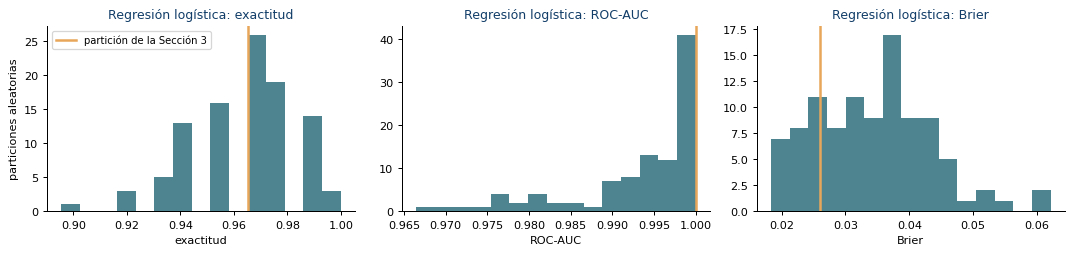

Regresión logística: exactitud en test en 100 particiones: mín. 0.895, máx. 1.000, 95% central [0.919, 0.994]
Gradient boosting supera a la regresión logística en 37% de las particiones, empata en 21% y pierde en 42%.


In [ ]:
N_LOTTERY = 100
lottery = []
for s in range(N_LOTTERY):
    tr, rest = train_test_split(df, test_size=0.30, stratify=df["target"], random_state=s)
    _, te = train_test_split(rest, test_size=0.50, stratify=rest["target"], random_state=s)
    sc = MinMaxScaler().fit(tr[FEATURES])
    X_tr, X_te = sc.transform(tr[FEATURES]), sc.transform(te[FEATURES])
    for name, clf in [(LOGREG, LogisticRegression(max_iter=5000)), (GBOOST, HistGradientBoostingClassifier(random_state=SEED))]:
        p = clf.fit(X_tr, tr["target"]).predict_proba(X_te)[:, 1]
        lottery.append({"seed": s, "modelo": name, **metrics(te["target"].to_numpy(), p)})
lottery = pd.DataFrame(lottery)
lr_runs = lottery[lottery["modelo"] == LOGREG]

fig, axes = plt.subplots(1, 3, figsize=(12, 2.9))
for ax, m in zip(axes, [ACC, AUC, BRIER]):
    ax.hist(lr_runs[m], bins=15, color=TEAL, alpha=0.85)
    ax.axvline(baseline_results[0][m], color=ORANGE, lw=2, label="partición de la Sección 3")
    ax.set_title(f"{LOGREG}: {m}"); ax.set_xlabel(m)
axes[0].set_ylabel("particiones aleatorias"); axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

wide = lottery.pivot(index="seed", columns="modelo", values=ACC)
print(f"{LOGREG}: exactitud en test en {N_LOTTERY} particiones: mín. {lr_runs[ACC].min():.3f}, "
      f"máx. {lr_runs[ACC].max():.3f}, 95% central [{lr_runs[ACC].quantile(0.025):.3f}, {lr_runs[ACC].quantile(0.975):.3f}]")
print(f"Gradient boosting supera a la regresión logística en {(wide[GBOOST] > wide[LOGREG]).mean():.0%} de las particiones, empata en "
      f"{(wide[GBOOST] == wide[LOGREG]).mean():.0%} y pierde en {(wide[GBOOST] < wide[LOGREG]).mean():.0%}.")

Mismo modelo, mismos datos, solo cambia la partición: la exactitud en test de la regresión logística va de **0,895 a 1,000** (95% central: 0,919–0,994), y nuestra partición (0,965, línea naranja) es solo una extracción. Cambia incluso el ganador: gradient boosting supera a la regresión logística en el 37% de las particiones, empata en el 21% y pierde en el 42%. Ninguna diferencia entre modelos menor que esta dispersión puede atribuirse a los modelos. Con 569 pacientes, un test mayor dejaría al entrenamiento sin datos, así que la solución estándar es **usar a todos los pacientes como test por turnos** (validación cruzada) y cuantificar la incertidumbre de forma explícita.

<a id="section102" name="section102"></a>
## <font color="#004D7F" size=5>10.2. Protocolo: validación cruzada estratificada repetida</font>

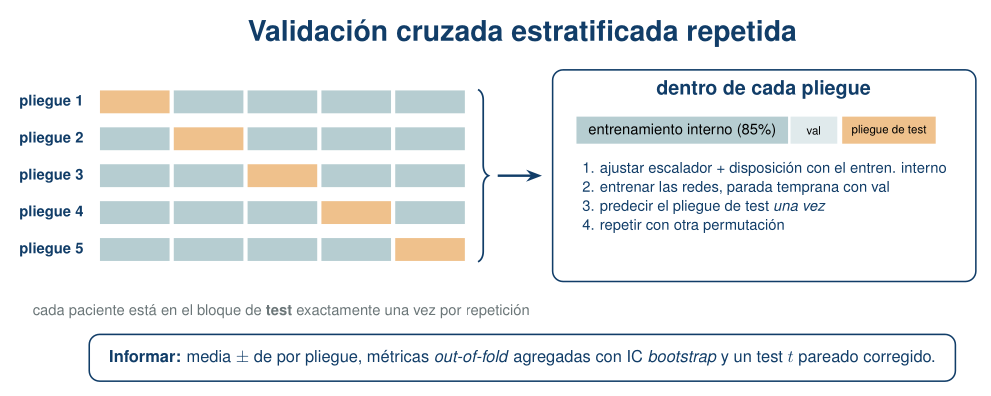

<p style="text-align:center; color:#555555;"><em><strong>Figura 7.</strong> Validación cruzada estratificada repetida. En cada repetición los pacientes se barajan y se dividen en cinco pliegues estratificados; cada pliegue es el test una vez. Dentro de cada pliegue se reserva una partición de validación interna para la parada temprana, y todo lo que se aprende (escalador, disposición de la imagen, pesos de la red) usa solo la partición de entrenamiento interna. «de» = desviación estándar.</em></p>

| Decisión de diseño | Elección | Motivo |
|---|---|---|
| Remuestreo externo | `RepeatedStratifiedKFold`, 5 pliegues × 2 repeticiones = **10 particiones entrenamiento/test** | cada paciente es test una vez por repetición; la estratificación mantiene un 37% de malignos en cada pliegue; las repeticiones promedian la suerte de una permutación concreta |
| Validación interna | 15% de cada conjunto de entrenamiento externo, estratificado | se usa **solo** para la parada temprana de las redes |
| Qué se ajusta en cada pliegue | escalador, **disposición IGTD**, huellas de píxeles y la comprobación de escala de la Sección 7.1, pesos de las redes | todo con la partición de entrenamiento interna: el pliegue de test nunca influye en nada que se aprenda |
| Modelos de referencia | entrenados con todo el conjunto de entrenamiento externo (entrenamiento interno + validación) | no necesitan parada temprana; todos los modelos ven los mismos pacientes de entrenamiento externos |
| Hiperparámetros | fijados de antemano (Sección 9.1) | si se ajustan, la búsqueda debe hacerse **dentro** de cada conjunto de entrenamiento externo (validación cruzada anidada), nunca con los pliegues de test |
| Emparejamiento | mismos pliegues y misma semilla para todos los modelos de un pliegue | las diferencias entre modelos pueden analizarse pliegue a pliegue (diseño pareado) |
| Métrica principal | **puntuación de Brier**, declarada antes de ejecutar | regla de puntuación propia, sensible a la calibración, no se satura como el ROC-AUC; la exactitud equilibrada es la métrica secundaria |

<div class="alert alert-info">
<strong>¿Por qué la puntuación de Brier y no la log-loss?</strong><br>
Ambas son reglas de puntuación propias, pero nuestras redes se entrenan con suavizado de etiquetas de 0,05, lo que limita su confianza a unos 0,975. Eso añade un mínimo de −ln 0,975 ≈ 0,025 a la log-loss de cada paciente bien clasificado, una penalización que los modelos de referencia no pagan. El mismo límite solo añade 0,025² ≈ 0,0006 a la puntuación de Brier, así que la comparación sigue siendo justa.
</div>

<a id="section103" name="section103"></a>
## <font color="#004D7F" size=5>10.3. Ejecución del protocolo</font>

La primera celda prepara un pliegue: divide el conjunto de entrenamiento externo, ajusta el escalador y un IGTD **nuevo** con la partición de entrenamiento interna, calcula las huellas de la disposición de ese pliegue y lleva todas las particiones a la escala de entrenamiento con `restore_scale()` (Sección 7.1), comprobando que la restauración es exacta.

In [ ]:
N_SPLITS, N_REPEATS = 5, 2          # 10 particiones entrenamiento/test; usa más repeticiones para un artículo final
VAL_SIZE = 0.15                     # validación interna, solo para la parada temprana
MAX_RESTORE_ERROR = 0.01            # tolerancia de la comprobación de escala de la Sección 7.1
MODEL_COL = "modelo"
MODEL_ORDER = [LOGREG, GBOOST, "CNN", "ViT", "HyCNN", "HyViT"]

def make_fold_data(train_idx, test_idx, seed):
    outer = df.iloc[train_idx]
    inner, val = train_test_split(outer, test_size=VAL_SIZE, stratify=outer["target"], random_state=seed)
    splits = {"train": inner.reset_index(drop=True), "val": val.reset_index(drop=True),
              "test": df.iloc[test_idx].reset_index(drop=True)}
    # Todo lo que se aprende se ajusta solo con la partición de entrenamiento interna
    fold_scaler = MinMaxScaler().fit(splits["train"][FEATURES])
    tab = {s: fold_scaler.transform(d[FEATURES]).astype(np.float32) for s, d in splits.items()}
    method = make_method(seed)
    raw_fold = to_images(method, "cv_fold", splits, verbose=False)
    fold_masks = feature_footprints(method, splits["train"])
    img, worst_error = {}, 0.0
    for s in splits:
        img[s], best, errors = restore_scale(raw_fold[s], tab[s], fold_masks)
        worst_error = max(worst_error, errors[best])
    if worst_error > MAX_RESTORE_ERROR:
        print(f"  AVISO: error de restauración de escala {worst_error:.3f} > {MAX_RESTORE_ERROR}")
    y_fold = {s: d["target"].to_numpy() for s, d in splits.items()}
    return {"img": img, "tab": tab, "y": y_fold, "restore_error": worst_error, "masks": fold_masks}

def fit_baselines(data, seed):
    # Los modelos de referencia no necesitan parada temprana: usan todo el entrenamiento externo (entrenamiento interno + validación)
    X_fit = np.vstack([data["tab"]["train"], data["tab"]["val"]])
    y_fit = np.concatenate([data["y"]["train"], data["y"]["val"]])
    lr = LogisticRegression(max_iter=5000).fit(X_fit, y_fit)
    gb = HistGradientBoostingClassifier(random_state=seed).fit(X_fit, y_fit)
    return {LOGREG: lr.predict_proba(data["tab"]["test"])[:, 1], GBOOST: gb.predict_proba(data["tab"]["test"])[:, 1]}

El bucle principal entrena los seis modelos en cada uno de los 10 pliegues y guarda dos cosas: las **métricas de cada pliegue** y la **probabilidad *out-of-fold*** de cada paciente en cada repetición. En nuestra ejecución con CPU tardó 707 s (unos 12 minutos); reduce `N_REPEATS` a 1 para una ejecución rápida o auméntalo para un artículo final (el tiempo crece linealmente).

In [ ]:
cv = RepeatedStratifiedKFold(n_splits=N_SPLITS, n_repeats=N_REPEATS, random_state=SEED)
oof = {name: np.full((N_REPEATS, len(df)), np.nan) for name in MODEL_ORDER}   # probabilidades out-of-fold
fold_rows = []
t_start = time.time()
for f, (train_idx, test_idx) in enumerate(cv.split(df[FEATURES], df["target"])):
    repeat, fold = divmod(f, N_SPLITS)
    seed = SEED + f
    fold_data = make_fold_data(train_idx, test_idx, seed)
    assert fold_data["img"]["train"].shape[-2:] == (H, W), "el tamaño de imagen debe ser el mismo en todos los pliegues"
    probs = fit_baselines(fold_data, seed)
    for name, build in BUILDERS.items():
        set_seed(seed)                   # diseño pareado: en un pliegue, todas las redes parten de la misma semilla
        model, _ = train(build(), fold_data, seed=seed)
        probs[name] = predict_proba(model, fold_data["img"]["test"], fold_data["tab"]["test"])
    for name, p in probs.items():
        oof[name][repeat, test_idx] = p
        fold_rows.append({"repeat": repeat, "fold": fold, MODEL_COL: name, **metrics(fold_data["y"]["test"], p)})
    print(f"repetición {repeat + 1}/{N_REPEATS} · pliegue {fold + 1}/{N_SPLITS} · {len(test_idx)} pacientes de test · "
          f"Brier: " + ", ".join(f"{name} {brier_score_loss(fold_data['y']['test'], p):.3f}" for name, p in probs.items())
          + f" · {time.time() - t_start:4.0f} s")

cv_results = pd.DataFrame(fold_rows)
assert not any(np.isnan(v).any() for v in oof.values()), "cada paciente debe ser test una vez por repetición"

repetición 1/2 · pliegue 1/5 · 114 pacientes de test · Brier: Regresión logística 0.027, Gradient boosting 0.008, CNN 0.022, ViT 0.021, HyCNN 0.016, HyViT 0.035 ·   71 s
repetición 1/2 · pliegue 2/5 · 114 pacientes de test · Brier: Regresión logística 0.044, Gradient boosting 0.047, CNN 0.050, ViT 0.084, HyCNN 0.050, HyViT 0.060 ·  130 s
repetición 1/2 · pliegue 3/5 · 114 pacientes de test · Brier: Regresión logística 0.042, Gradient boosting 0.042, CNN 0.039, ViT 0.033, HyCNN 0.029, HyViT 0.029 ·  190 s
repetición 1/2 · pliegue 4/5 · 114 pacientes de test · Brier: Regresión logística 0.028, Gradient boosting 0.018, CNN 0.022, ViT 0.058, HyCNN 0.020, HyViT 0.026 ·  250 s
repetición 1/2 · pliegue 5/5 · 113 pacientes de test · Brier: Regresión logística 0.024, Gradient boosting 0.029, CNN 0.014, ViT 0.010, HyCNN 0.009, HyViT 0.010 ·  318 s
repetición 2/2 · pliegue 1/5 · 114 pacientes de test · Brier: Regresión logística 0.030, Gradient boosting 0.021, CNN 0.028, ViT 0.016, HyCNN 0.022, H

<a id="section104" name="section104"></a>
## <font color="#004D7F" size=5>10.4. Estimaciones de rendimiento</font>

Analizamos los resultados desde dos ángulos complementarios:

- **Por pliegue** (media ± desviación estándar sobre los 10 pliegues): cuánto varía el resultado de una partición entrenamiento/test. La desviación estándar *no* es un intervalo de confianza: los pliegues comparten la mayor parte de sus datos de entrenamiento, así que no son independientes.
- ***Out-of-fold* agregado**: cada paciente tiene exactamente una predicción de test por repetición, así que cada métrica puede calcularse con los 569 pacientes a la vez y promediarse sobre las repeticiones. Un ***bootstrap* sobre pacientes** (1000 remuestreos) da un intervalo de confianza del 95% que refleja el número finito de pacientes de test; no incluye la variabilidad debida al reentrenamiento, de la que se ocupan los tests de la Sección 10.5.

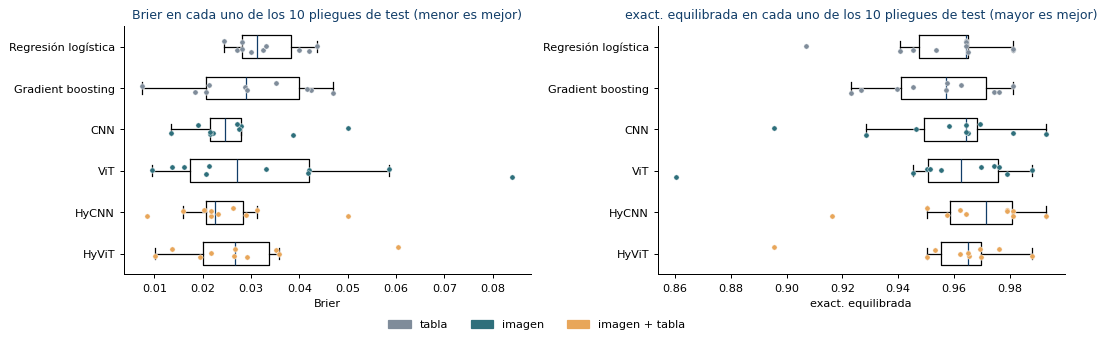

Media ± desviación estándar por pliegue


,Brier,exact. equilibrada,ROC-AUC,F1 (maligno),exactitud
modelo,,,,,
Regresión logística,0.033 ± 0.007,0.957 ± 0.022,0.994 ± 0.006,0.953 ± 0.024,0.967 ± 0.016
Gradient boosting,0.029 ± 0.012,0.954 ± 0.020,0.991 ± 0.007,0.947 ± 0.023,0.961 ± 0.016
CNN,0.027 ± 0.011,0.957 ± 0.028,0.994 ± 0.006,0.952 ± 0.030,0.966 ± 0.020
ViT,0.034 ± 0.023,0.955 ± 0.036,0.992 ± 0.007,0.944 ± 0.042,0.960 ± 0.027
HyCNN,0.025 ± 0.011,0.966 ± 0.022,0.995 ± 0.006,0.958 ± 0.024,0.969 ± 0.017
HyViT,0.028 ± 0.014,0.959 ± 0.025,0.995 ± 0.005,0.951 ± 0.029,0.964 ± 0.020


In [ ]:
METRIC_COLS = [BRIER, BACC, AUC, F1, ACC]
KIND_COLOUR = {LOGREG: GREY, GBOOST: GREY, "CNN": TEAL, "ViT": TEAL, "HyCNN": ORANGE, "HyViT": ORANGE}

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
for ax, m in zip(axes, [BRIER, BACC]):
    values = [cv_results.loc[cv_results[MODEL_COL] == name, m].to_numpy() for name in MODEL_ORDER]
    ax.boxplot(values, vert=False, widths=0.55, showfliers=False, medianprops={"color": NAVY})
    jitter = np.random.default_rng(SEED)
    for i, (name, v) in enumerate(zip(MODEL_ORDER, values), start=1):
        ax.scatter(v, i + jitter.uniform(-0.15, 0.15, len(v)), s=18, color=KIND_COLOUR[name],
                   edgecolor="white", linewidth=0.4, zorder=3)
    ax.set_yticks(range(1, len(MODEL_ORDER) + 1))
    ax.set_yticklabels(MODEL_ORDER)
    ax.invert_yaxis()
    better = "menor es mejor" if m == BRIER else "mayor es mejor"
    ax.set_title(f"{m} en cada uno de los {len(values[0])} pliegues de test ({better})")
    ax.set_xlabel(m)
fig.legend(handles=[Patch(color=GREY, label="tabla"), Patch(color=TEAL, label="imagen"),
                    Patch(color=ORANGE, label="imagen + tabla")],
           loc="lower center", ncol=3, frameon=False, bbox_to_anchor=(0.5, -0.06))
plt.tight_layout()
plt.show()

fold_table = pd.DataFrame({m: cv_results.groupby(MODEL_COL)[m].agg(lambda v: f"{v.mean():.3f} ± {v.std(ddof=1):.3f}")
                           for m in METRIC_COLS}).loc[MODEL_ORDER]
fold_table.index.name = MODEL_COL
print("Media ± desviación estándar por pliegue")
fold_table

In [ ]:
N_BOOT = 1000
y_all = df["target"].to_numpy()

# Versiones rápidas de las métricas para el bootstrap (comprobadas con scikit-learn abajo)
def brier_fast(t, p):
    return np.mean((p - t) ** 2)

def bacc_fast(t, p):
    pred = p >= 0.5
    return 0.5 * (pred[t == 1].mean() + (~pred[t == 0]).mean())

def auc_fast(t, p):
    # Formulación de Mann-Whitney del ROC-AUC (los empates cuentan 1/2)
    r = stats.rankdata(p)
    n1 = t.sum(); n0 = len(t) - n1
    return (r[t == 1].sum() - n1 * (n1 + 1) / 2) / (n1 * n0)

POOLED = {BRIER: (brier_fast, brier_score_loss), BACC: (bacc_fast, balanced_accuracy_score), AUC: (auc_fast, roc_auc_score)}
p_check = oof[LOGREG][0]
for m, (fast, reference) in POOLED.items():
    ref_value = reference(y_all, (p_check >= 0.5).astype(int)) if m == BACC else reference(y_all, p_check)
    assert np.isclose(fast(y_all, p_check), ref_value), m

rng = np.random.default_rng(SEED)
boot_idx = [rng.integers(0, len(y_all), len(y_all)) for _ in range(N_BOOT)]
rows = []
for name in MODEL_ORDER:
    P = oof[name]                                    # (N_REPEATS, pacientes)
    row = {MODEL_COL: name}
    for m, (fast, _) in POOLED.items():
        point = np.mean([fast(y_all, p) for p in P])
        boot = [np.mean([fast(y_all[i], p[i]) for p in P]) for i in boot_idx]
        lo, hi = np.percentile(boot, [2.5, 97.5])
        row[m] = f"{point:.3f} [{lo:.3f}, {hi:.3f}]"
    rows.append(row)
pooled_table = pd.DataFrame(rows).set_index(MODEL_COL)
print(f"Estimación out-of-fold agregada sobre {len(y_all)} pacientes, media de {N_REPEATS} repeticiones [IC bootstrap del 95%]")
pooled_table

Estimación out-of-fold agregada sobre 569 pacientes, media de 2 repeticiones [IC bootstrap del 95%]


,Brier,exact. equilibrada,ROC-AUC
modelo,,,
Regresión logística,"0.033 [0.026, 0.041]","0.957 [0.937, 0.974]","0.993 [0.986, 0.998]"
Gradient boosting,"0.029 [0.019, 0.041]","0.954 [0.936, 0.971]","0.990 [0.982, 0.997]"
CNN,"0.027 [0.019, 0.035]","0.956 [0.939, 0.973]","0.993 [0.986, 0.998]"
ViT,"0.034 [0.023, 0.046]","0.955 [0.938, 0.970]","0.987 [0.978, 0.994]"
HyCNN,"0.025 [0.018, 0.033]","0.966 [0.951, 0.979]","0.994 [0.988, 0.998]"
HyViT,"0.028 [0.018, 0.038]","0.959 [0.944, 0.974]","0.991 [0.985, 0.997]"


**Qué muestran las estimaciones.** Los seis modelos están cerca del techo y sus intervalos se solapan: Brier agregado entre 0,025 (HyCNN) y 0,034 (ViT), exactitud equilibrada 0,954–0,966 y ROC-AUC 0,987–0,994. El ViT es el modelo menos estable (Brier 0,034 ± 0,023 por pliegue; en su peor pliegue, Brier 0,084 y exactitud equilibrada 0,86), lo contrario de lo que sugería la partición única de la Sección 9. Descriptivamente, cada híbrido mejora a su versión solo imagen (HyCNN 0,025 frente a CNN 0,027; HyViT 0,028 frente a ViT 0,034); si estas diferencias son reales se contrasta a continuación.

<a id="section105" name="section105"></a>
## <font color="#004D7F" size=5>10.5. ¿Son reales las diferencias? Tests estadísticos corregidos</font>

Para comparar un modelo con la referencia usamos las diferencias pareadas de los 10 pliegues, $d_j = s_j^{\text{modelo}} - s_j^{\text{ref}}$. Un test $t$ pareado ingenuo trata las $J$ diferencias como independientes, pero los conjuntos de entrenamiento de los distintos pliegues se solapan mucho, así que las puntuaciones por pliegue están correlacionadas positivamente y el test ingenuo **subestima la varianza y encuentra demasiadas diferencias «significativas»**. El **test $t$ de remuestreo corregido** (Nadeau y Bengio, 2003), en su versión para validación cruzada repetida (Bouckaert y Frank, 2004), infla la varianza con la razón entre el tamaño de test y el de entrenamiento:

$$
t = \frac{\bar d}{\sqrt{\left(\dfrac{1}{J} + \dfrac{n_{\text{test}}}{n_{\text{train}}}\right)\hat\sigma^2_d}}, \qquad \frac{n_{\text{test}}}{n_{\text{train}}} = \frac{1}{k-1}, \qquad \text{gl} = J-1,
$$

con $J = k \cdot r$ pliegues en total. Fijamos la referencia (regresión logística), la métrica principal (Brier) y el nivel de significación (0,05) **antes** de ver los resultados, y corregimos las 5 comparaciones de cada métrica con el método de **Holm**. La tabla también incluye el intervalo de confianza del 95% de la diferencia media, construido con la misma varianza corregida, y el valor $p$ ingenuo para comparar.

In [ ]:
def corrected_ttest(diff, n_splits=N_SPLITS, level=0.95):
    # Test t corregido para k-fold repetido (Nadeau y Bengio, 2003; Bouckaert y Frank, 2004)
    d = np.asarray(diff, dtype=float)
    J = len(d)
    se = np.sqrt((1 / J + 1 / (n_splits - 1)) * d.var(ddof=1))
    if se == 0:
        return {"mean": d.mean(), "t": np.nan, "p": 1.0 if d.mean() == 0 else np.nan, "lo": d.mean(), "hi": d.mean()}
    t = d.mean() / se
    q = stats.t.ppf(0.5 + level / 2, df=J - 1)
    return {"mean": d.mean(), "t": t, "p": 2 * stats.t.sf(abs(t), df=J - 1),
            "lo": d.mean() - q * se, "hi": d.mean() + q * se}

def holm(pvalues):
    # Ajuste secuencial de Holm para comparaciones múltiples
    p = np.nan_to_num(np.asarray(pvalues, dtype=float), nan=1.0)
    adjusted, running = np.empty_like(p), 0.0
    for rank, i in enumerate(np.argsort(p)):
        running = max(running, (len(p) - rank) * p[i])
        adjusted[i] = min(1.0, running)
    return adjusted

REFERENCE, ALPHA = LOGREG, 0.05          # fijados antes de ver los resultados
others = [name for name in MODEL_ORDER if name != REFERENCE]
rows = []
for m, lower_is_better in [(BRIER, True), (BACC, False)]:
    per_fold = cv_results.pivot_table(index=["repeat", "fold"], columns=MODEL_COL, values=m)
    tests = [corrected_ttest(per_fold[name] - per_fold[REFERENCE]) for name in others]
    p_holm = holm([t_["p"] for t_ in tests])
    for name, res, p_adj in zip(others, tests, p_holm):
        naive = stats.ttest_rel(per_fold[name], per_fold[REFERENCE]).pvalue
        improves = res["mean"] < 0 if lower_is_better else res["mean"] > 0
        verdict = ("mejor" if improves else "peor") if p_adj < ALPHA else "sin evidencia de diferencia"
        rows.append({"métrica": m, MODEL_COL: name, "dif. media": res["mean"],
                     "IC 95% (corregido)": f"[{res['lo']:+.4f}, {res['hi']:+.4f}]",
                     "p ingenuo": naive, "p corregido": res["p"], "p Holm": p_adj,
                     "veredicto": verdict})
tests_table = pd.DataFrame(rows).set_index(["métrica", MODEL_COL])
print(f"Diferencias respecto a {REFERENCE} ({N_SPLITS} pliegues x {N_REPEATS} repeticiones)")
tests_table.round(4)

Diferencias respecto a Regresión logística (5 pliegues x 2 repeticiones)


dif. media  IC 95% (corregido)  \
métrica            modelo                                              
Brier              Gradient boosting     -0.0037  [-0.0148, +0.0074]   
                   CNN                   -0.0060  [-0.0136, +0.0016]   
                   ViT                    0.0012  [-0.0251, +0.0275]   
                   HyCNN                 -0.0081  [-0.0161, -0.0001]   
                   HyViT                 -0.0050  [-0.0188, +0.0088]   
exact. equilibrada Gradient boosting     -0.0023  [-0.0187, +0.0140]   
                   CNN                   -0.0001  [-0.0181, +0.0179]   
                   ViT                   -0.0017  [-0.0324, +0.0291]   
                   HyCNN                  0.0097  [-0.0084, +0.0278]   
                   HyViT                  0.0028  [-0.0189, +0.0245]   

                                      p ingenuo  p corregido  p Holm  \
métrica            modelo                                              
Brier              Gradient boosting     0.1893       0.4673  1.0000   
                   CNN                   0.0089       0.1097  0.4387   
                   ViT                   0.8541       0.9217  1.0000   
                   HyCNN                 0.0020       0.0475  0.2376   
                   HyViT                 0.1565       0.4299  1.0000   
exact. equilibrada Gradient boosting     0.5610       0.7544  1.0000   
                   CNN                   0.9754       0.9868  1.0000   
                   ViT                   0.8229       0.9047  1.0000   
                   HyCNN                 0.0491       0.2552  1.0000   
                   HyViT                 0.6001       0.7781  1.0000   

                                                        veredicto  
métrica            modelo                                          
Brier              Gradient boosting  sin evidencia de diferencia  
                   CNN                sin evidencia de diferencia  
                   ViT                sin evidencia de diferencia  
                   HyCNN              sin evidencia de diferencia  
                   HyViT              sin evidencia de diferencia  
exact. equilibrada Gradient boosting  sin evidencia de diferencia  
                   CNN                sin evidencia de diferencia  
                   ViT                sin evidencia de diferencia  
                   HyCNN              sin evidencia de diferencia  
                   HyViT              sin evidencia de diferencia

**Resultado.** Tras la corrección de Holm, **ningún modelo difiere significativamente de la regresión logística**, ni en Brier ni en exactitud equilibrada. El caso más cercano es la HyCNN (Brier −0,0081; IC 95% corregido [−0,0161; −0,0001]; p corregido = 0,048; p de Holm = 0,24): sugerente, pero no es evidencia una vez consideradas las cinco comparaciones.

- **El test ingenuo nos habría engañado:** da p = 0,002 para la HyCNN y p = 0,009 para la CNN. Ignorar el solapamiento entre conjuntos de entrenamiento es uno de los errores estadísticos más frecuentes en los artículos de aprendizaje automático.
- **«Sin evidencia de diferencia» no es evidencia de equivalencia.** El intervalo del ViT abarca unos ±0,027 en Brier; para afirmar equivalencia hay que fijar de antemano la menor diferencia relevante (p. ej., 0,01) y comprobar que todo el intervalo queda dentro.
- Con 10 pliegues los tests tienen poca potencia; más repeticiones estabilizan las estimaciones, pero no crean pacientes nuevos.

<a id="section106" name="section106"></a>
## <font color="#004D7F" size=5>10.6. Cómo comunicar los resultados</font>

<div class="alert alert-info">
<strong>Lista de comprobación.</strong> (1) Protocolo: validación cruzada estratificada repetida, validación interna para la parada temprana, todo lo aprendido ajustado dentro de los pliegues de entrenamiento, hiperparámetros fijados de antemano y semillas. (2) Estimaciones con intervalos de confianza. (3) Métrica principal y referencia declaradas de antemano; test corregido con ajuste por multiplicidad. (4) Evidencia separada de la interpretación.
</div>

**Nuestros resultados, tal como aparecerían en un artículo:**

> *«Con validación cruzada estratificada repetida 5×2, la red híbrida HyCNN obtuvo la menor puntuación de Brier out-of-fold agregada (0,025; IC 95% 0,018–0,033) frente a 0,033 (0,026–0,041) de la regresión logística. Tras el ajuste de Holm, el test t de remuestreo corregido no encontró evidencia de diferencia respecto a la regresión logística para ningún modelo (HyCNN: diferencia media −0,008; IC 95% −0,016 a −0,0001; p ajustado por Holm = 0,24).»*

**Interpretación.** En este conjunto cercano al techo, las redes basadas en imágenes y las híbridas son **competitivas, pero no demostrablemente mejores** que una regresión logística, un resultado honesto y legítimo. Los beneficios de las imágenes sintéticas descritos en la literatura aparecen sobre todo con pocas muestras, muchas variables o interacciones complejas, y deben demostrarse con este mismo protocolo.

---
<div style="text-align: right">
<font size=5>
<a href="#indice">Volver al índice</a>
</font>
</div>

<a id="section11" name="section11"></a>
# <font color="#004D7F" size=6>11. Explicabilidad de la CNN y el ViT</font>

Un modelo entrenado con imágenes sintéticas es doblemente una caja negra: hay que explicar la red **y** traducir los píxeles a variables. Como conocemos la huella de cada variable (Sección 5), cualquier mapa de píxeles puede sumarse en una importancia por variable (Figura 8). Explicamos la CNN y el ViT entrenados con la partición de la Sección 9.

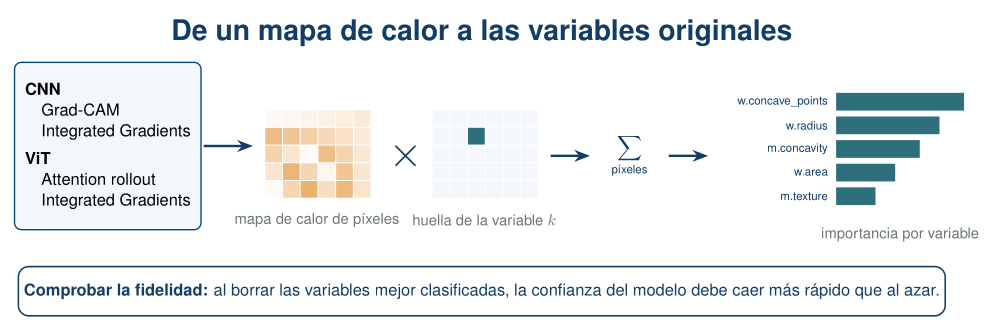

<p style="text-align:center; color:#555555;"><em><strong>Figura 8.</strong> De un mapa de calor a las variables originales. Una explicación a nivel de píxel se multiplica por la huella de cada variable y se suma, dando un valor de importancia por variable; un test de borrado comprueba después que la ordenación es fiel.</em></p>

<a id="section111" name="section111"></a>
## <font color="#004D7F" size=5>11.1. Tres herramientas de explicación</font>

| Método | Modelo | Qué muestra |
|---|---|---|
| **Grad-CAM** | CNN | Qué regiones de los últimos mapas convolucionales empujan la predicción hacia la clase explicada |
| **Integrated Gradients (IG)** | CNN y ViT | Cuánto contribuye cada píxel respecto a una imagen de referencia (el paciente de entrenamiento medio) |
| **Attention rollout** | ViT | De qué tokens toma información el token [CLS], a través de todas las capas |

In [ ]:
def per_feature(pixel_map, reduce="sum"):
    # Agrega un mapa de píxeles en un valor por variable usando las huellas
    agg = np.sum if reduce == "sum" else np.mean
    return np.array([agg(pixel_map[m]) if m.any() else 0.0 for m in masks])

def grad_cam(model, img, sign=1.0):
    # Grad-CAM sobre la salida de la última etapa convolucional de la CNN
    model.eval()
    store = {}
    hook = model.encoder.stage2.register_forward_hook(lambda mod, inp, out: store.update(act=out))
    logit = model(torch.as_tensor(img[None], device=DEVICE))
    hook.remove()
    act = store["act"]
    grad = torch.autograd.grad(sign * logit.sum(), act)[0]
    weights = grad.mean(dim=(2, 3), keepdim=True)            # importancia de cada canal
    cam = F.relu((weights * act).sum(1, keepdim=True))       # evidencia a favor de la clase explicada
    cam = F.interpolate(cam, size=img.shape[-2:], mode="bilinear", align_corners=False)[0, 0]
    return (cam / (cam.max() + 1e-12)).detach().cpu().numpy()

BASELINE = X_img["train"].mean(0)          # entrada de referencia: el paciente de entrenamiento medio

def integrated_gradients(model, img, steps=64, sign=1.0):
    # IG: gradiente medio a lo largo del camino recto desde la referencia hasta la entrada
    model.eval()
    x = torch.as_tensor(img[None], device=DEVICE)
    b = torch.as_tensor(BASELINE[None], device=DEVICE)
    alphas = (torch.arange(steps, device=DEVICE, dtype=torch.float32) + 0.5) / steps
    path = (b + alphas.view(-1, 1, 1, 1) * (x - b)).requires_grad_(True)
    grads = torch.autograd.grad(sign * model(path).sum(), path)[0]
    return ((x - b) * grads.mean(0, keepdim=True))[0, 0].detach().cpu().numpy()

@torch.no_grad()
def attention_rollout(model, img):
    # Multiplica las matrices de atención promediadas por cabeza de todas las capas (más la identidad residual)
    model.eval()
    model(torch.as_tensor(img[None], device=DEVICE))
    blocks = model.encoder.blocks
    n = blocks[0].last_attn.shape[-1]
    eye = torch.eye(n, device=DEVICE)
    rollout = eye
    for block in blocks:
        a = block.last_attn[0].mean(0) + eye
        rollout = (a / a.sum(-1, keepdim=True)) @ rollout
    cls_to_tokens = rollout[0, 1:].reshape(model.encoder.grid).cpu().numpy()
    return np.kron(cls_to_tokens, np.ones((PATCH, PATCH)))   # de vuelta a resolución de píxel

**Comprobación: completitud.** Integrated Gradients tiene una propiedad útil: las atribuciones suman el cambio en la salida del modelo entre la referencia y la entrada. Si los dos números de abajo son parecidos, la implementación funciona correctamente.

In [ ]:
cnn, vit = models["CNN"], models["ViT"]
x0 = X_img["test"][patient]
for name, model in [("CNN", cnn), ("ViT", vit)]:
    with torch.no_grad():
        f_x = model(torch.as_tensor(x0[None], device=DEVICE)).item()
        f_b = model(torch.as_tensor(BASELINE[None], device=DEVICE)).item()
    ig = integrated_gradients(model, x0)
    print(f"{name}: suma de IG = {ig.sum():+.3f}   |   f(entrada) - f(referencia) = {f_x - f_b:+.3f}")

CNN: suma de IG = +8.289   |   f(entrada) - f(referencia) = +8.271
ViT: suma de IG = +4.184   |   f(entrada) - f(referencia) = +4.182


Ambas comprobaciones se cumplen: 8,289 frente a 8,271 en la CNN y 4,184 frente a 4,182 en el ViT (diferencias inferiores al 0,3%, debidas a la aproximación de la integral con 64 pasos).

<a id="section112" name="section112"></a>
## <font color="#004D7F" size=5>11.2. Explicación local</font>

Explicamos el paciente maligno de test mostrado en la galería. Cada mapa de calor se superpone a la imagen del paciente y los gráficos de barras traducen los mapas de IG a las variables originales.

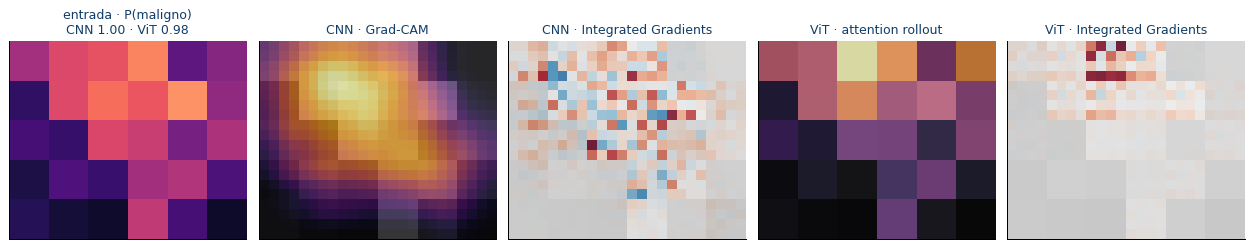

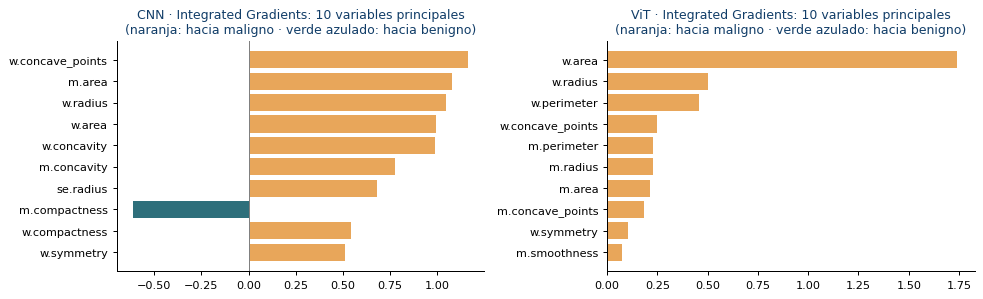

In [ ]:
maps = {
    "CNN · Grad-CAM": grad_cam(cnn, x0),
    "CNN · Integrated Gradients": integrated_gradients(cnn, x0),
    "ViT · attention rollout": attention_rollout(vit, x0),
    "ViT · Integrated Gradients": integrated_gradients(vit, x0),
}
p_cnn = predict_proba(cnn, x0[None], X_tab["test"][patient:patient + 1])[0]
p_vit = predict_proba(vit, x0[None], X_tab["test"][patient:patient + 1])[0]

fig, axes = plt.subplots(1, 5, figsize=(14, 3.1))
axes[0].imshow(x0[0], cmap="magma", vmin=0, vmax=1, interpolation="nearest")
axes[0].set_title(f"entrada · P(maligno)\nCNN {p_cnn:.2f} · ViT {p_vit:.2f}")
for ax, (title, m) in zip(axes[1:], maps.items()):
    ax.imshow(x0[0], cmap="gray", vmin=0, vmax=1, interpolation="nearest")
    if "Integrated" in title:
        lim = np.abs(m).max() + 1e-12
        ax.imshow(m, cmap="RdBu_r", vmin=-lim, vmax=lim, alpha=0.8, interpolation="nearest")
    else:
        ax.imshow(m, cmap="inferno", alpha=0.6, interpolation="nearest")
    ax.set_title(title)
for ax in axes:
    ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout()
plt.show()

def short(name):
    return {"mean": "m.", "error": "se.", "worst": "w."}[group_of(name)] + measure_of(name)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
for ax, key in zip(axes, ["CNN · Integrated Gradients", "ViT · Integrated Gradients"]):
    contrib = per_feature(maps[key])
    top = np.argsort(-np.abs(contrib))[:10][::-1]
    ax.barh([short(FEATURES[k]) for k in top], contrib[top],
            color=[ORANGE if contrib[k] > 0 else TEAL for k in top])
    ax.axvline(0, color="grey", lw=0.8)
    ax.set_title(f"{key}: 10 variables principales\n(naranja: hacia maligno · verde azulado: hacia benigno)")
plt.tight_layout()
plt.show()

Ambos modelos están seguros con este paciente (P(maligno) = 1,00 en la CNN y 0,98 en el ViT). La evidencia de la CNN procede sobre todo de variables de tamaño y contorno (w.concave_points, m.area, w.radius), con m.compactness empujando ligeramente hacia benigno; el ViT se apoya ante todo en w.area.

- **Grad-CAM** es grueso: trabaja a la resolución de la última capa convolucional (aquí, la mitad del tamaño de entrada) y después se reescala. Indica *dónde*, no exactamente *qué píxel*.
- **Integrated Gradients** es exacto a nivel de píxel y tiene signo. Con IGTD cada bloque de 4x4 es una variable, así que el gráfico de barras es una lectura directa del mapa.
- **Attention rollout** muestra por dónde encamina el ViT la información. No es específico de la clase: la atención dice qué *mira* el modelo, no en qué dirección empuja la decisión.

<a id="section113" name="section113"></a>
## <font color="#004D7F" size=5>11.3. Explicación global</font>

Promediamos la contribución absoluta de IG de cada variable sobre todo el conjunto de test, para ambos modelos, y comparamos las ordenaciones entre sí y con los coeficientes de la regresión logística de referencia.

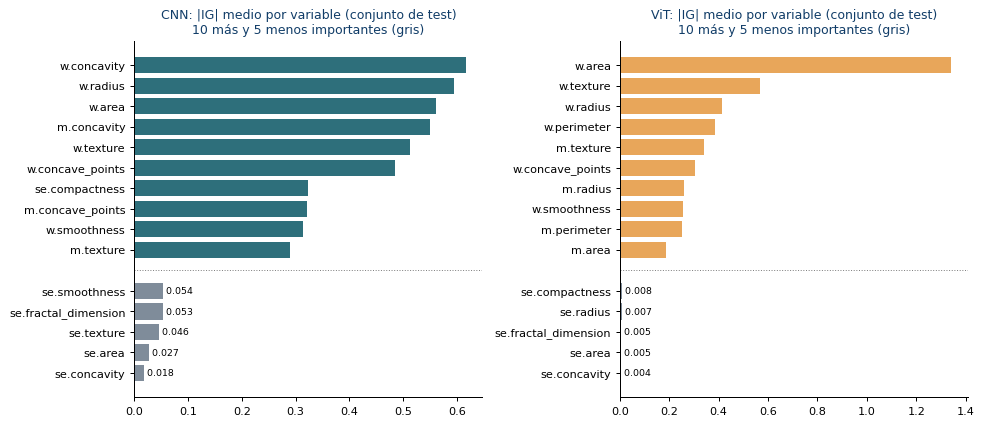

Correlación de rangos de Spearman  CNN vs ViT:                       +0.56
Correlación de rangos de Spearman  CNN vs |coef. logístico|: +0.71
Correlación de rangos de Spearman  ViT vs |coef. logístico|: +0.75


In [ ]:
def global_importance(model):
    return np.mean([np.abs(per_feature(integrated_gradients(model, x, steps=32))) for x in X_img["test"]], axis=0)

imp = {"CNN": global_importance(cnn), "ViT": global_importance(vit)}
coef = np.abs(logreg.coef_[0])

TOP, BOTTOM = 10, 5                       # variables más y menos importantes que se muestran
fig, axes = plt.subplots(1, 2, figsize=(11, 4.8))
for ax, (name, v) in zip(axes, imp.items()):
    order = np.argsort(-v)
    shown = list(order[:TOP]) + list(order[-BOTTOM:])
    ypos = list(range(TOP)) + [TOP + 1 + i for i in range(BOTTOM)]          # un hueco separa ambos grupos
    ax.barh(ypos, v[shown], color=[TEAL if name == "CNN" else ORANGE] * TOP + [GREY] * BOTTOM)
    ax.set_yticks(ypos)
    ax.set_yticklabels([short(FEATURES[k]) for k in shown])
    ax.invert_yaxis()
    ax.axhline(TOP, color="grey", lw=0.8, ls=":")
    for yy, k in zip(ypos[TOP:], shown[TOP:]):
        ax.text(v[k], yy, f" {v[k]:.3f}", va="center", fontsize=7.5)
    ax.set_title(f"{name}: |IG| medio por variable (conjunto de test)\n{TOP} más y {BOTTOM} menos importantes (gris)")
plt.tight_layout()
plt.show()

print(f"Correlación de rangos de Spearman  CNN vs ViT:                       {spearmanr(imp['CNN'], imp['ViT']).correlation:+.2f}")
print(f"Correlación de rangos de Spearman  CNN vs |coef. logístico|: {spearmanr(imp['CNN'], coef).correlation:+.2f}")
print(f"Correlación de rangos de Spearman  ViT vs |coef. logístico|: {spearmanr(imp['ViT'], coef).correlation:+.2f}")

**Cómo leer las ordenaciones globales.** Ambos modelos se apoyan en variables de tamaño y contorno, y ambas ordenaciones coinciden moderadamente con los coeficientes de la regresión logística (Spearman 0,71 y 0,75), pero solo en parte entre sí (0,56): la CNN reparte la importancia entre w.concavity, w.radius, w.area y m.concavity, mientras que el ViT está dominado por w.area.

Las cinco variables **menos importantes** son todas errores estándar (CNN: se.smoothness, se.fractal_dimension, se.texture, se.area, se.concavity; ViT: se.compactness, se.radius, se.fractal_dimension, se.area, se.concavity), con |IG| medio casi nulo (≤ 0,054 en la CNN y ≤ 0,008 en el ViT). Algunas apenas tienen señal de clase, pero se.area y se.radius sí: son redundantes con la media y el peor valor de la misma medida, así que el modelo no las necesita. **Poca importancia significa «no la usa este modelo», no «no es informativa».**

<div class="alert alert-info">
<strong>¿Por qué aparece w.perimeter en el ViT y no en la CNN?</strong><br>
Cada gráfico muestra las 12 primeras de su propio modelo, y en la CNN w.perimeter queda por debajo del puesto 12. Radio, perímetro y área contienen casi la misma información (peor radio frente a peor perímetro r = 0,993 y frente a peor área r = 0,985 en la partición de entrenamiento), así que una red puede usar cualquier combinación de ellas, e IG atribuye el mérito a las que esa red ha usado realmente. Dos modelos igual de buenos pueden repartirlo de forma distinta. Con variables muy correlacionadas, compara las importancias <strong>por grupos</strong> (p. ej., la suma de IG de radio, perímetro y área), no una a una.
</div>

<a id="section114" name="section114"></a>
## <font color="#004D7F" size=5>11.4. ¿Son fieles las explicaciones?</font>

Un mapa de calor solo es útil si refleja lo que el modelo usa realmente. Un test sencillo: **eliminar** las variables una a una, de la más a la menos importante, sustituyendo sus píxeles por el valor medio de entrenamiento, y observar cuánta confianza conserva el modelo en la clase verdadera. Si la ordenación es fiel, la confianza debería caer **más rápido** que al eliminar las variables en orden aleatorio. Seguimos la confianza en lugar del ROC-AUC porque, en este conjunto de datos fácil, el AUC permanece saturado.

CNN: confianza tras eliminar 5 / 10 variables -> menos importantes primero 0.947 / 0.945 · azar 0.937 / 0.897 · más importantes primero 0.881 / 0.733 (sin eliminar: 0.946)
ViT: confianza tras eliminar 5 / 10 variables -> menos importantes primero 0.965 / 0.965 · azar 0.959 / 0.951 · más importantes primero 0.839 / 0.631 (sin eliminar: 0.965)


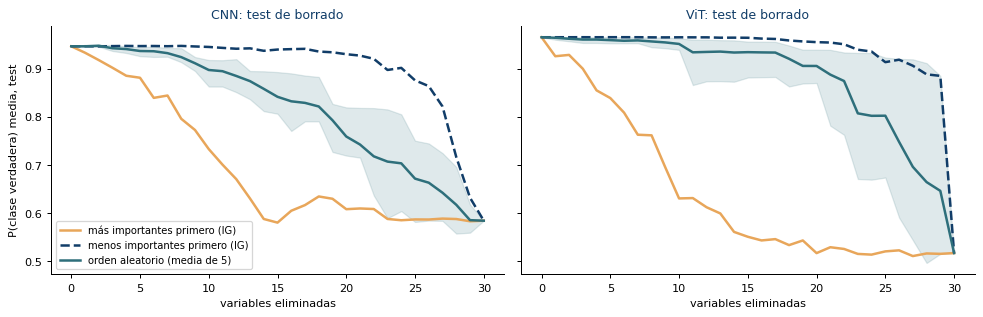

In [ ]:
def confidence(model, X):
    # Probabilidad media que el modelo asigna a la clase VERDADERA de cada paciente de test
    p = predict_proba(model, X, X_tab["test"])
    return np.mean(np.where(y["test"] == 1, p, 1 - p))

def deletion_curve(model, order):
    X = X_img["test"].copy()
    scores = [confidence(model, X)]
    for k in order:
        m = masks[k]
        X[:, :, m] = BASELINE[:, m]          # "borrar" la variable k: sustituirla por su valor medio
        scores.append(confidence(model, X))
    return np.array(scores)

rng = np.random.default_rng(SEED)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for ax, (name, model) in zip(axes, [("CNN", cnn), ("ViT", vit)]):
    most = deletion_curve(model, np.argsort(-imp[name]))           # más importantes primero
    least = deletion_curve(model, np.argsort(imp[name]))           # menos importantes primero
    random_runs = np.array([deletion_curve(model, rng.permutation(len(FEATURES))) for _ in range(5)])
    steps = np.arange(len(most))
    ax.plot(steps, most, color=ORANGE, lw=2, label="más importantes primero (IG)")
    ax.plot(steps, least, color=NAVY, lw=2, ls="--", label="menos importantes primero (IG)")
    ax.plot(steps, random_runs.mean(0), color=TEAL, lw=2, label="orden aleatorio (media de 5)")
    ax.fill_between(steps, random_runs.min(0), random_runs.max(0), color=TEAL, alpha=0.15)
    ax.set_title(f"{name}: test de borrado"); ax.set_xlabel("variables eliminadas")
    print(f"{name}: confianza tras eliminar 5 / 10 variables -> menos importantes primero {least[5]:.3f} / {least[10]:.3f} · "
          f"azar {random_runs.mean(0)[5]:.3f} / {random_runs.mean(0)[10]:.3f} · más importantes primero {most[5]:.3f} / {most[10]:.3f} "
          f"(sin eliminar: {most[0]:.3f})")
axes[0].set_ylabel("P(clase verdadera) media, test"); axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

**Resultado.** Eliminar las variables en el orden de IG reduce la confianza en la clase verdadera mucho más rápido que eliminarlas al azar (tras 10 variables: 0,733 frente a 0,897 en la CNN y 0,631 frente a 0,951 en el ViT), mientras que eliminar primero las **menos** importantes la deja prácticamente igual (CNN 0,946 → 0,945; ViT 0,965 → 0,965). Las dos curvas de IG encierran a la aleatoria, que es lo que deben hacer unas ordenaciones fieles.

<div class="alert alert-warning">
<strong>Advertencias.</strong><br>
Una explicación muestra lo que usa el <strong>modelo</strong>, no lo que <strong>causa</strong> el cáncer. IG depende de la <strong>referencia</strong> (aquí, el paciente medio); una imagen negra contaría otra historia. Estas explicaciones proceden de <strong>un</strong> modelo entrenado con una partición; para comprobar que son estables, repítelas con los modelos de varios pliegues de la validación cruzada y compara las ordenaciones. Las explicaciones son más difíciles de rastrear con disposiciones <strong>difuminadas</strong> o solapadas, por eso los métodos con una correspondencia uno a uno entre píxel y variable, como IGTD o TINTO sin difuminado, facilitan la auditoría. Acompaña siempre los mapas de calor de un <strong>test de fidelidad</strong> como la curva de borrado anterior.
</div>

<a id="section115" name="section115"></a>
## <font color="#004D7F" size=5>11.5. ¿Mejora el modelo sin las variables menos importantes?</font>

El test de borrado elimina variables de un modelo entrenado con todas ellas. Otra pregunta distinta es si un modelo **reentrenado sin** las variables menos importantes funciona mejor o peor. Dentro de cada pliegue de la Sección 10 ordenamos las variables con IG sobre la partición de **validación** interna (nunca con el pliegue de test, que sería fuga de información), sustituimos las 5 o 10 menos importantes por una constante en todas las particiones, reentrenamos la CNN y el ViT con la misma semilla y los comparamos con el modelo completo mediante el test corregido. Eliminar las 5 **más** importantes sirve de contraste. Se mantiene la disposición IGTD, de modo que solo cambia la información, no la geometría de la imagen.

In [ ]:
# Ablación con reentrenamiento: neutralizar las k variables menos (o más) importantes, reentrenar y evaluar.
# La ordenación se calcula con IG sobre la partición de VALIDACIÓN interna de cada pliegue, nunca con el pliegue de test:
# elegir variables con los datos de test y evaluar después con esos mismos datos sería fuga de información.
ABL_REPEATS = 1          # 1 -> primeros 5 pliegues de la Sección 10 (unos 10 min con CPU); 2 -> los 10 pliegues (unos 20 min)
VARIANTS = {"sin las 5 menos importantes": ("least", 5),
            "sin las 10 menos importantes": ("least", 10),
            "sin las 5 más importantes": ("most", 5)}           # contraste: elimina la evidencia más fuerte
FULL = "las 30 variables"

def ig_importance(model, X, baseline, fold_masks, steps=32):
    # |IG| medio por variable sobre las imágenes X, con la referencia y las huellas del propio pliegue
    model.eval()
    b = torch.as_tensor(baseline[None], device=DEVICE)
    alphas = (torch.arange(steps, device=DEVICE, dtype=torch.float32) + 0.5) / steps
    total = np.zeros(len(fold_masks))
    for x_np in X:
        x = torch.as_tensor(x_np[None], device=DEVICE)
        path = (b + alphas.view(-1, 1, 1, 1) * (x - b)).requires_grad_(True)
        grads = torch.autograd.grad(model(path).sum(), path)[0]
        attr = ((x - b) * grads.mean(0, keepdim=True))[0, 0].detach().cpu().numpy()
        total += np.abs([attr[m].sum() if m.any() else 0.0 for m in fold_masks])
    return total / len(X)

def neutralise(data, feats, baseline, fold_masks):
    # Sustituye las variables elegidas por una constante (media de entrenamiento) en TODAS las particiones: no aportan información
    img = {}
    for split, X in data["img"].items():
        X = X.copy()
        for k in feats:
            X[:, :, fold_masks[k]] = baseline[:, fold_masks[k]]
        img[split] = X
    return {**data, "img": img}

def evaluate(model, data):
    p = predict_proba(model, data["img"]["test"], data["tab"]["test"])
    t = data["y"]["test"]
    return {BRIER: brier_score_loss(t, p), BACC: balanced_accuracy_score(t, (p >= 0.5).astype(int))}

abl_rows, least_counts = [], {"CNN": {}, "ViT": {}}
cv = RepeatedStratifiedKFold(n_splits=N_SPLITS, n_repeats=N_REPEATS, random_state=SEED)   # mismos pliegues que la Sección 10
t_start = time.time()
for f, (train_idx, test_idx) in enumerate(cv.split(df[FEATURES], df["target"])):
    repeat, fold = divmod(f, N_SPLITS)
    if repeat >= ABL_REPEATS:
        break
    seed = SEED + f
    fd = make_fold_data(train_idx, test_idx, seed)
    base = fd["img"]["train"].mean(0)
    visible = np.array([k for k, m in enumerate(fd["masks"]) if m.any()])
    for name in ["CNN", "ViT"]:
        set_seed(seed)
        model, _ = train(BUILDERS[name](), fd, seed=seed)
        abl_rows.append({"repeat": repeat, "fold": fold, "model": name, "variant": FULL, **evaluate(model, fd)})
        imp_val = ig_importance(model, fd["img"]["val"], base, fd["masks"])
        order = visible[np.argsort(imp_val[visible])]                   # menos importantes primero
        for k in order[:5]:
            least_counts[name][FEATURES[k]] = least_counts[name].get(FEATURES[k], 0) + 1
        for label, (which, n_drop) in VARIANTS.items():
            feats = order[:n_drop] if which == "least" else order[::-1][:n_drop]
            reduced = neutralise(fd, feats, base, fd["masks"])
            set_seed(seed)
            model_r, _ = train(BUILDERS[name](), reduced, seed=seed)
            abl_rows.append({"repeat": repeat, "fold": fold, "model": name, "variant": label, **evaluate(model_r, reduced)})
    print(f"pliegue {f + 1}/{ABL_REPEATS * N_SPLITS} terminado · {time.time() - t_start:4.0f} s")

abl = pd.DataFrame(abl_rows)
summary = []
for m in [BRIER, BACC]:
    tests = []
    for name in ["CNN", "ViT"]:
        full = abl[(abl["model"] == name) & (abl["variant"] == FULL)].set_index(["repeat", "fold"])[m]
        for label in VARIANTS:
            red = abl[(abl["model"] == name) & (abl["variant"] == label)].set_index(["repeat", "fold"])[m]
            res = corrected_ttest(red - full)
            tests.append(res)
            summary.append({"métrica": m, "modelo": name, "variante": label, "las 30": full.mean(), "reducido": red.mean(),
                            "dif. media": res["mean"], "IC 95% (corregido)": f"[{res['lo']:+.4f}, {res['hi']:+.4f}]",
                            "p corregido": res["p"]})
    for row, p_adj in zip(summary[-len(tests):], holm([t_["p"] for t_ in tests])):
        row["p Holm"] = p_adj
abl_table = pd.DataFrame(summary).set_index(["métrica", "modelo", "variante"])

for name, counts in least_counts.items():
    ranked = sorted(counts.items(), key=lambda kv: -kv[1])
    print(f"{name}: variables entre las 5 menos importantes (pliegues de {ABL_REPEATS * N_SPLITS}): "
          + ", ".join(f"{short(v)} ({c})" for v, c in ranked))
print("Brier: menor es mejor · exact. equilibrada: mayor es mejor · diferencia = reducido - las 30")
abl_table.round(4)

pliegue 1/5 terminado ·  152 s
pliegue 2/5 terminado ·  290 s
pliegue 3/5 terminado ·  437 s
pliegue 4/5 terminado ·  560 s
pliegue 5/5 terminado ·  672 s
CNN: variables entre las 5 menos importantes (pliegues de 5): se.smoothness (5), m.fractal_dimension (4), se.fractal_dimension (4), se.concavity (3), m.symmetry (2), se.texture (2), m.compactness (1), m.smoothness (1), w.fractal_dimension (1), se.compactness (1), se.perimeter (1)
ViT: variables entre las 5 menos importantes (pliegues de 5): se.symmetry (4), se.fractal_dimension (4), se.compactness (4), se.concavity (4), se.concave_points (3), se.perimeter (2), se.smoothness (2), se.texture (1), se.area (1)
Brier: menor es mejor · exact. equilibrada: mayor es mejor · diferencia = reducido - las 30


las 30  reducido  \
métrica            modelo variante                                         
Brier              CNN    sin las 5 menos importantes   0.0292    0.0315   
                          sin las 10 menos importantes  0.0292    0.0281   
                          sin las 5 más importantes     0.0292    0.0285   
                   ViT    sin las 5 menos importantes   0.0412    0.0331   
                          sin las 10 menos importantes  0.0412    0.0374   
                          sin las 5 más importantes     0.0412    0.0270   
exact. equilibrada CNN    sin las 5 menos importantes   0.9526    0.9476   
                          sin las 10 menos importantes  0.9526    0.9620   
                          sin las 5 más importantes     0.9526    0.9610   
                   ViT    sin las 5 menos importantes   0.9458    0.9565   
                          sin las 10 menos importantes  0.9458    0.9533   
                          sin las 5 más importantes     0.9458    0.9581   

                                                        dif. media  \
métrica            modelo variante                                   
Brier              CNN    sin las 5 menos importantes       0.0023   
                          sin las 10 menos importantes     -0.0012   
                          sin las 5 más importantes        -0.0008   
                   ViT    sin las 5 menos importantes      -0.0081   
                          sin las 10 menos importantes     -0.0037   
                          sin las 5 más importantes        -0.0141   
exact. equilibrada CNN    sin las 5 menos importantes      -0.0051   
                          sin las 10 menos importantes      0.0094   
                          sin las 5 más importantes         0.0084   
                   ViT    sin las 5 menos importantes       0.0107   
                          sin las 10 menos importantes      0.0074   
                          sin las 5 más importantes         0.0123   

                                                        IC 95% (corregido)  \
métrica            modelo variante                                           
Brier              CNN    sin las 5 menos importantes   [-0.0094, +0.0140]   
                          sin las 10 menos importantes  [-0.0123, +0.0100]   
                          sin las 5 más importantes     [-0.0168, +0.0153]   
                   ViT    sin las 5 menos importantes   [-0.0271, +0.0109]   
                          sin las 10 menos importantes  [-0.0172, +0.0098]   
                          sin las 5 más importantes     [-0.0577, +0.0294]   
exact. equilibrada CNN    sin las 5 menos importantes   [-0.0539, +0.0438]   
                          sin las 10 menos importantes  [-0.0310, +0.0498]   
                          sin las 5 más importantes     [-0.0461, +0.0628]   
                   ViT    sin las 5 menos importantes   [-0.0270, +0.0484]   
                          sin las 10 menos importantes  [-0.0238, +0.0387]   
                          sin las 5 más importantes     [-0.0452, +0.0698]   

                                                        p corregido  p Holm  
métrica            modelo variante                                           
Brier              CNN    sin las 5 menos importantes        0.6173     1.0  
                          sin las 10 menos importantes       0.7860     1.0  
                          sin las 5 más importantes          0.9026     1.0  
                   ViT    sin las 5 menos importantes        0.3045     1.0  
                          sin las 10 menos importantes       0.4870     1.0  
                          sin las 5 más importantes          0.4180     1.0  
exact. equilibrada CNN    sin las 5 menos importantes        0.7881     1.0  
                          sin las 10 menos importantes       0.5541     1.0  
                          sin las 5 más importantes          0.6913     1.0  
                   ViT    sin las 5 menos importantes      

**Resultado.** Ninguna variante difiere significativamente del modelo completo (p de Holm = 1,0 en todas las comparaciones, 5 pliegues). Eliminar las 5 o 10 variables menos importantes cambia la puntuación de Brier entre −0,008 y +0,002, dentro del ruido entre pliegues: en este conjunto cercano al techo, descartarlas ni ayuda ni perjudica.

- **El contraste es más revelador: eliminar las 5 más importantes tampoco perjudica** (Brier 0,0285 frente a 0,0292 en la CNN). Las redes reentrenadas compensan con las variables restantes, muy correlacionadas. IG describe lo que usa un modelo *ya entrenado*, no qué variables son imprescindibles para el problema.
- Las aparentes mejoras del ViT (p. ej., 0,0270 frente a 0,0412) reflejan su inestabilidad, con un pliegue de Brier 0,084 como en la Sección 10, más que un efecto de las variables; los intervalos son amplios (hasta [−0,058; +0,029]) y 5 pliegues dan poca potencia.
- Las variables menos importantes son estables entre pliegues y casi todas errores estándar: se.smoothness en 5 de 5 pliegues en la CNN; se.symmetry, se.fractal_dimension, se.compactness y se.concavity en 4 de 5 en el ViT.
- Los modelos completos reproducen los valores de la Sección 10 en los mismos pliegues (CNN 0,029; ViT 0,041), como cabe esperar con semillas fijas.

---
<div style="text-align: right">
<font size=5>
<a href="#indice">Volver al índice</a>
</font>
</div>

<a id="section12" name="section12"></a>
# <font color="#004D7F" size=6>12. Conclusiones</font>

- **Una imagen sintética es una elección de representación.** TINTOlib ofrece muchas y exponen la misma fila de formas muy distintas.
- **Ajustar solo con los datos de entrenamiento**, transformar todo lo demás con el método congelado y **comprobar que la misma fila produce siempre la misma imagen**: una transformación dependiente del lote desplaza silenciosamente los datos de validación y test.
- Las **redes híbridas** conservan los números exactos en una rama MLP mientras la rama de visión aprovecha la disposición; además recuperan variables que la imagen puede ocultar.
- **Una partición es una anécdota, no una estimación.** Hay que comunicar validación cruzada repetida con todos los pasos aprendidos dentro de los pliegues de entrenamiento, intervalos de confianza y tests corregidos y ajustados por multiplicidad frente a modelos tabulares sólidos, declarando de antemano la métrica principal y la referencia.
- **La explicabilidad debe diseñarse desde el principio:** usar disposiciones trazables, devolver los píxeles a las variables y comprobar la fidelidad de las explicaciones.
- **Lo que ha mostrado este notebook:** el mejor modelo en la partición única (el ViT) es el más variable en la validación cruzada, y ninguna red es significativamente mejor que la regresión logística en este conjunto cercano al techo. Las explicaciones son fieles (test de borrado en ambos sentidos), pero reentrenar sin las variables menos, o incluso más, importantes no cambia nada significativo: con variables redundantes, la importancia describe al modelo, no al problema.

---
<div style="text-align: right">
<font size=5>
<a href="#indice">Volver al índice</a>
</font>
</div>

<a id="section13" name="section13"></a>
# <font color="#004D7F" size=6>13. Ejercicios</font>

1. **Otra disposición.** Pon `METHOD = "TINTO"` en la Sección 7 y vuelve a ejecutar todo, incluida la Sección 10. ¿Qué variables desaparecen, qué hipótesis elige la Sección 7.1 y es TINTO mejor o peor que IGTD según el test corregido? (Ambas ejecuciones usan los mismos pliegues y semillas, así que la comparación es pareada; guarda `cv_results` antes de volver a ejecutar.)
2. **Más repeticiones.** Pon `N_REPEATS = 5`. ¿Cómo cambian los intervalos *bootstrap*, los intervalos de confianza corregidos y los veredictos? ¿Por qué apenas cambia la anchura del intervalo *bootstrap*?
3. **Ajuste sin fuga de información.** Elige la tasa de aprendizaje de la CNN entre {1e-3, 5e-4, 2e-4} *dentro* de cada pliegue, usando solo la partición de validación interna, y evalúa el modelo elegido en el pliegue de test (validación cruzada anidada). Compara con la receta fija.
4. **Quitar una salvaguarda.** Vuelve a entrenar sin suavizado de etiquetas o sin calentamiento. Observa las curvas de validación de la Sección 9 *y* la puntuación de Brier de la Sección 10: ¿cuál te dice más?
5. **Difuminado y Grad-CAM.** Entrena la CNN con imágenes de `TINTO(..., blur=True)` y compara los mapas de Grad-CAM con la versión sin difuminar.
6. **Imágenes centradas en instancias.** Alimenta la CNN con imágenes de `Clusters(algorithm="kmedoids")`. ¿Qué significa ahora un píxel y puede la Sección 11 seguir asignándolo a variables?
7. **Estabilidad de las explicaciones.** Conserva la CNN de cada pliegue de la Sección 10 y calcula su importancia global de IG sobre su propio pliegue de test. ¿Qué estabilidad tiene la ordenación de las 5 variables principales entre pliegues?

---
<div style="text-align: right">
<font size=5>
<a href="#indice">Volver al índice</a>
</font>
</div>

<a id="section14" name="section14"></a>
# <font color="#004D7F" size=6>14. Referencias</font>

- **TINTOlib**. Documentación: https://tintolib.readthedocs.io · Código: https://github.com/oeg-upm/TINTOlib
- **Curso intensivo de TINTOlib** (notebooks y vídeos): https://github.com/oeg-upm/TINTOlib-Crash_Course
- **Evaluación y estadística.** Nadeau, C. y Bengio, Y. (2003). *Inference for the generalization error*. Machine Learning, 52(3), 239–281 · Bouckaert, R. R. y Frank, E. (2004). *Evaluating the replicability of significance tests for comparing learning algorithms*. PAKDD, LNCS 3056, 3–12 · Dietterich, T. G. (1998). *Approximate statistical tests for comparing supervised classification learning algorithms*. Neural Computation, 10(7), 1895–1923 · Varma, S. y Simon, R. (2006). *Bias in error estimation when using cross-validation for model selection*. BMC Bioinformatics, 7, 91 · Holm, S. (1979). *A simple sequentially rejective multiple test procedure*. Scandinavian Journal of Statistics, 6(2), 65–70 · Brier, G. W. (1950). *Verification of forecasts expressed in terms of probability*. Monthly Weather Review, 78(1), 1–3.
- **Explicabilidad.** Selvaraju, R. R. et al. (2017). *Grad-CAM*. ICCV · Sundararajan, M. et al. (2017). *Axiomatic attribution for deep networks*. ICML · Abnar, S. y Zuidema, W. (2020). *Quantifying attention flow in transformers*. ACL.
- **Blogs & Tutorials**: https://www.manuelcastillo.eu/blog/
- **Artículos de referencia**:  
    - Liu, J., Castillo-Cara, M. y García-Castro, R. (2026). *A comprehensive benchmark of spatial encoding methods for tabular data with deep neural networks*. Information Fusion, 130, 104088.
    - Liu, J., González-Fernández, D., Castillo-Cara, M. y García-Castro, R. (2025). *TINTOlib: A Python library for transforming tabular data into synthetic images for deep neural networks*. SoftwareX, 32, 102444.
    - Castillo-Cara, M. et al. (2025). *MIMO-based indoor localisation with hybrid neural networks*. IEEE Journal of Selected Topics in Signal Processing, 19(3), 559–571.
    - Escalera-González, F., Castillo-Cara, M. et al. (2026). *PermGrad: Interpretable hybrid neural networks with synthetic images for tabular data*. Knowledge-Based Systems, 350, 116507.
    - Mondragon-Ruiz, G., Liu, J., Castillo-Cara, M., & García-Castro, R. (2026). Interpretable CNN–KAN hybrid architectures for tabular data with synthetic image encoding. Information Processing & Management, 63(8), 104954.
    - Martínez-Moreno, S., Liu, J., Castillo-Cara, M., Suni-Lopez, F., & García-Castro, R. (2026). CLUSTERS: Instance-Centric Synthetic Images for Tabular Learning and Functional Analysis of Hybrid Fusion.

---
<div style="text-align: right">
<font size=5>
<a href="#indice">Volver al índice</a>
</font>
</div>